# Early Detection of Pre-Cancerous Colorectal Polyps (MHIST)

**Title:** Uncertainty-Aware Explainable Deep Learning for Early Detection of Pre-Cancerous Colorectal Polyps in Histopathology

**Goal:** look at a microscope image of a colon polyp and say whether it is
- **HP**: hyperplastic polyp (benign, harmless), or
- **SSA**: sessile serrated adenoma (**pre-cancerous**: can turn into colorectal cancer).

The model also says **how sure it is**. If it is not sure, it says **"refer to doctor"**.

**Dataset:** MHIST: 3,152 images, each one checked by 7 pathologists.
**Models:** ConvNeXt-Base (CNN), Swin-Base (Transformer), and our **proposed** ConvNeXt + uncertainty (evidential) model.
**Base paper:** Sivaroopan et al., WACV 2025 (IEEE/CVF).



## Step 1: Import Libraries
We install two extra libraries: **timm** (ready-made image models) and **grad-cam** (heatmaps). Then we import everything we need and create the output folders.

In [1]:
!pip install -q "timm>=1.0.9" "grad-cam>=1.5.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'                             # use one GPU (two GPUs caused memory errors)
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'   # helps GPU memory

import glob, json, math, random, shutil, time, zipfile, datetime, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from PIL import Image, ImageFilter, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

from skimage.color import rgb2hed, hed2rgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, balanced_accuracy_score,
                             roc_curve, confusion_matrix, classification_report)
from scipy.stats import spearmanr
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

warnings.filterwarnings('ignore')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = (DEVICE == 'cuda')            # half precision on GPU = faster
print('PyTorch:', torch.__version__, '| timm:', timm.__version__, '| device:', DEVICE)

PyTorch: 2.11.0+cu128 | timm: 1.0.29 | device: cuda


In [3]:
# ----- Output folders -----
PROJECT_DIR     = '/kaggle/working/MHIST_Project'
CHECKPOINT_DIR  = PROJECT_DIR + '/checkpoints'    # trained models
RESULTS_DIR     = PROJECT_DIR + '/results'        # tables and predictions
FIGURES_DIR     = PROJECT_DIR + '/figures'        # plots
REPORTS_DIR     = PROJECT_DIR + '/reports'        # PDF reports for single images
FINAL_MODEL_DIR = PROJECT_DIR + '/final_model'    # everything the app needs

for folder in [CHECKPOINT_DIR, RESULTS_DIR, FIGURES_DIR, REPORTS_DIR, FINAL_MODEL_DIR]:
    os.makedirs(folder, exist_ok=True)

# ----- Find the models trained earlier (searches every attached input) -----
found_models = []
for root, dirs, files in os.walk('/kaggle/input', followlinks=True):
    if 'best.pth' in files:
        found_models.append(os.path.join(root, 'best.pth'))
print('Trained models found in inputs:', len(found_models))

# each model is at .../MHIST_Project/checkpoints/<run name>/best.pth -> 3 folders up = project folder
old_projects = sorted(set(os.path.dirname(os.path.dirname(os.path.dirname(p))) for p in found_models))
for old_folder in old_projects:
    print('Copying earlier models and results from:', old_folder)
    shutil.copytree(old_folder, PROJECT_DIR, dirs_exist_ok=True)

ready = [run for run in os.listdir(CHECKPOINT_DIR)
         if os.path.exists(f'{CHECKPOINT_DIR}/{run}/best.pth') and os.path.exists(f'{CHECKPOINT_DIR}/{run}/done.json')]
print('Trained models ready to use:', len(ready), 'of 9')
if len(ready) < 9:
    print('WARNING: models missing. Attached inputs:', os.listdir('/kaggle/input'))
    for name in os.listdir('/kaggle/input'):
        print('  ', name, '->', os.listdir(f'/kaggle/input/{name}')[:10])

def set_seed(seed):
    # same seed = same random numbers = repeatable results
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(0)
CLASS_NAMES = ['HP (benign)', 'SSA (pre-cancer)']

Trained models found in inputs: 0
Trained models ready to use: 18 of 9


## Step 2: Load Dataset
MHIST gives us:
- `images` : 3,152 colon polyp images (224 x 224 pixels)
- `annotations.csv` : for every image, the final label (HP or SSA), **how many of the 7 pathologists said SSA**, and whether it belongs to the official **train** or **test** set.

In [4]:
# 1. Read annotations.csv
csv_files = [p for p in glob.glob('/kaggle/input/**/annotations.csv', recursive=True) if 'MHIST_Project' not in p]
assert csv_files, 'annotations.csv not found -> Add Input -> MHIST dataset'
annotations = pd.read_csv(csv_files[0])
annotations.columns = [c.strip() for c in annotations.columns]
display(annotations.head())

def find_column(word):
    # find the column whose name contains this word
    for column in annotations.columns:
        if word in column.lower():
            return column
    raise ValueError('No column with: ' + word)

image_col = find_column('image')       # 'Image Name'
label_col = find_column('label')       # 'Majority Vote Label'
votes_col = find_column('number')      # 'Number of Annotators who Selected SSA (Out of 7)'
split_col = find_column('partition')   # 'Partition'

,Image Name,Majority Vote Label,Number of Annotators who Selected SSA (Out of 7),Partition
0,MHIST_aaa.png,SSA,6,train
1,MHIST_aab.png,HP,0,train
2,MHIST_aac.png,SSA,5,train
3,MHIST_aae.png,HP,1,train
4,MHIST_aaf.png,SSA,5,train


In [5]:
# 2. Find the image files
image_names = annotations[image_col].astype(str).str.strip()
wanted = set(image_names)

def find_images(folder):
    found = {}
    for path in glob.glob(folder + '/**/*.png', recursive=True):
        name = os.path.basename(path)
        if name in wanted:
            found[name] = path
    return found

image_paths = find_images('/kaggle/input')
if len(image_paths) < len(wanted):              # images are still inside images.zip -> unzip them
    for zip_path in glob.glob('/kaggle/input/**/*.zip', recursive=True):
        if 'MHIST_Project' not in zip_path:
            zipfile.ZipFile(zip_path).extractall('/tmp/mhist')
    image_paths = find_images('/tmp/mhist')
print('Images found:', len(image_paths))

# 3. One clean table: one row per image
df = pd.DataFrame()
df['path']  = image_names.map(image_paths)
df['label'] = (annotations[label_col].astype(str).str.strip().str.upper() == 'SSA').astype(int)   # 1 = SSA, 0 = HP
df['split'] = annotations[split_col].astype(str).str.strip().str.lower()                           # train / test
df['n_ssa'] = annotations[votes_col].astype(int)                                                   # pathologists (out of 7) who said SSA
display(df.head())

Images found: 3152


,path,label,split,n_ssa
0,/kaggle/input/datasets/jiteshankam/mhist-datas...,1,train,6
1,/kaggle/input/datasets/jiteshankam/mhist-datas...,0,train,0
2,/kaggle/input/datasets/jiteshankam/mhist-datas...,1,train,5
3,/kaggle/input/datasets/jiteshankam/mhist-datas...,0,train,1
4,/kaggle/input/datasets/jiteshankam/mhist-datas...,1,train,5


## Step 3: EDA (Exploratory Data Analysis)
Before training we look at the data: how many images of each class, how the pathologists voted, and what the images look like.

Total images : 3152
HP  (benign)    : 2162
SSA (pre-cancer): 990


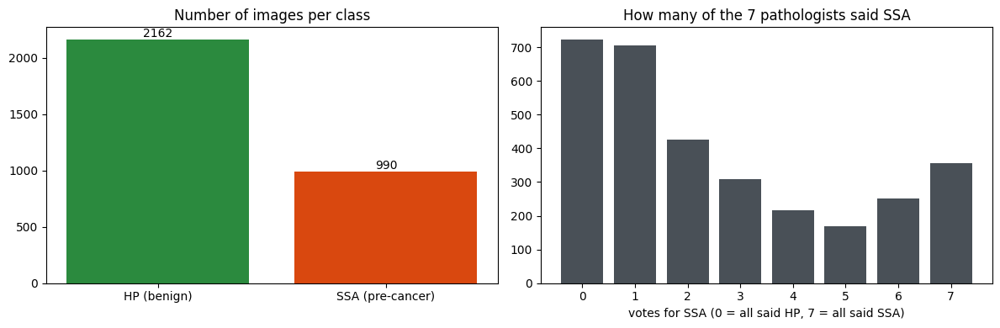

In [6]:
print('Total images :', len(df))
print('HP  (benign)    :', (df['label'] == 0).sum())
print('SSA (pre-cancer):', (df['label'] == 1).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts = df['label'].map({0: 'HP (benign)', 1: 'SSA (pre-cancer)'}).value_counts()
axes[0].bar(class_counts.index, class_counts.values, color=['#2b8a3e', '#d9480f'])
axes[0].set_title('Number of images per class')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 20, str(v), ha='center')

vote_counts = df['n_ssa'].value_counts().sort_index()
axes[1].bar(vote_counts.index, vote_counts.values, color='#495057')
axes[1].set_title('How many of the 7 pathologists said SSA')
axes[1].set_xlabel('votes for SSA (0 = all said HP, 7 = all said SSA)')
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/eda_counts.png', dpi=120); plt.show()

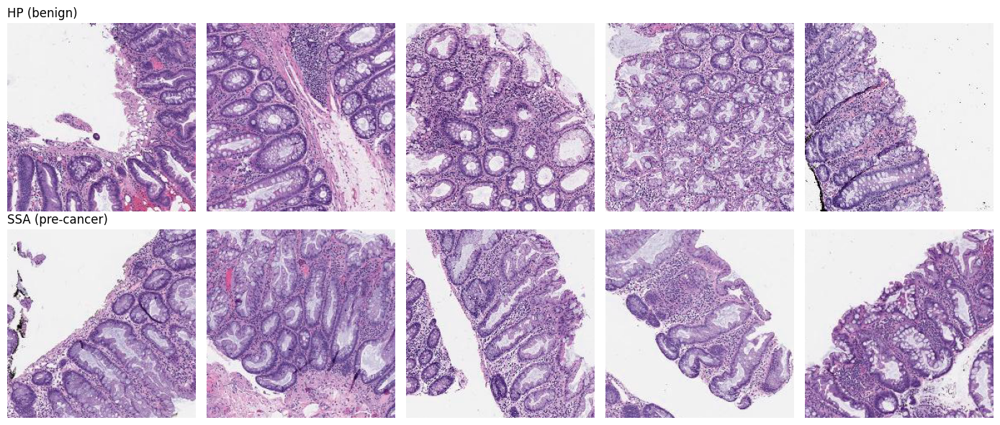

In [7]:
# Some example images of each class
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, label in enumerate([0, 1]):
    examples = df[df['label'] == label].sample(5, random_state=0)
    for col, path in enumerate(examples['path']):
        axes[row, col].imshow(Image.open(path).convert('RGB'))
        axes[row, col].axis('off')
    axes[row, 0].set_title(CLASS_NAMES[label], loc='left')
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/samples.png', dpi=120); plt.show()

## Step 4: Data Cleaning and Preprocessing
**Cleaning:** check that no image is missing, duplicated or broken.
**Preprocessing:** every image is resized and normalised the same way before it goes into a model:
- resize to **288 x 288** for ConvNeXt (bigger = small details are easier to see) and **224 x 224** for Swin
- normalise colours with the ImageNet mean and standard deviation (the models were pre-trained on ImageNet)

In [8]:
# ----- Cleaning checks -----
print('Missing images   :', df['path'].isna().sum())
print('Duplicate images :', df['path'].duplicated().sum())
assert df['path'].isna().sum() == 0, 'Some images are missing'

broken, sizes = [], {}
for path in tqdm(df['path'], desc='checking images'):
    try:
        size = Image.open(path).size
        sizes[size] = sizes.get(size, 0) + 1
    except Exception:
        broken.append(path)
print('Broken images    :', len(broken))
print('Image sizes      :', sizes)

Missing images   : 0
Duplicate images : 0


checking images:   0%|          | 0/3152 [00:00<?, ?it/s]

Broken images    : 0
Image sizes      : {(224, 224): 3152}


In [9]:
# ----- Preprocessing used for validation, testing and the app -----
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
IMAGE_SIZE = {'convnext': 288, 'swin': 224}

def get_test_transform(size):
    return T.Compose([
        T.Resize((size, size), antialias=True),     # resize
        T.ToTensor(),                               # image -> numbers between 0 and 1
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD),   # same colour scale as ImageNet
    ])

example = Image.open(df['path'][0]).convert('RGB')
tensor = get_test_transform(288)(example)
print('Original image size:', example.size, '-> model input shape:', tuple(tensor.shape))

Original image size: (224, 224) -> model input shape: (3, 288, 288)


## Step 5: Feature Engineering
Deep learning models learn image features by themselves, so here we create the **extra information** our method uses:

1. **Soft label `q`** = (pathologists who said SSA) / 7. Example: 6 of 7 said SSA -> q = 0.86. Our proposed model learns from this instead of a hard 0/1.
2. **Agreement** = how many pathologists agreed with the majority (4 to 7). Low agreement = a difficult image.
3. **Data augmentation** for training only: random crops, flips, rotations and **stain colour changes (HED)** so the model works on images from other labs too.

In [10]:
df['q'] = df['n_ssa'] / 7.0                                   # soft label
df['agreement'] = np.maximum(df['n_ssa'], 7 - df['n_ssa'])    # 4, 5, 6 or 7 pathologists agree

print('Pathologist agreement (lower = harder image):')
display(pd.crosstab(df['agreement'], df['label'].map({0: 'HP', 1: 'SSA'})).rename(index=lambda a: f'{a}/7 agree'))

Pathologist agreement (lower = harder image):


label,HP,SSA
agreement,,
4/7 agree,308,216
5/7 agree,426,168
6/7 agree,705,250
7/7 agree,723,356


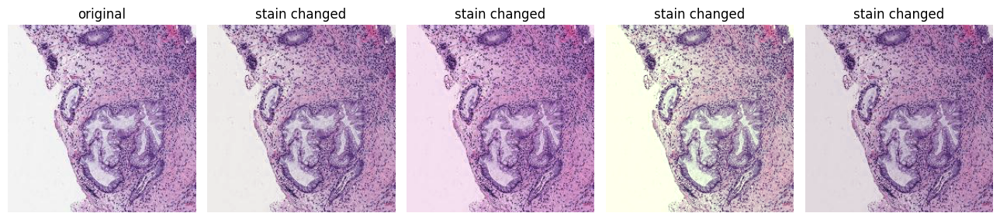

In [11]:
class StainAugmentation:
    # Randomly changes the strength of the pink (eosin) and purple (haematoxylin) stains,
    # so the model is not confused by colour differences between hospitals.
    def __init__(self, strength=0.05, probability=0.8):
        self.strength = strength
        self.probability = probability

    def __call__(self, image):
        if random.random() > self.probability:
            return image
        hed = rgb2hed(np.asarray(image, dtype=np.float32) / 255.0)          # split into stain channels
        scale = np.random.uniform(1 - self.strength, 1 + self.strength, 3)
        shift = np.random.uniform(-self.strength / 5, self.strength / 5, 3)
        rgb = np.clip(hed2rgb(hed * scale + shift), 0, 1)                     # back to a normal image
        return Image.fromarray((rgb * 255).astype(np.uint8))

def get_train_transform(size):
    return T.Compose([
        StainAugmentation(),
        T.RandomResizedCrop(size, scale=(0.8, 1.0), antialias=True),
        T.RandomHorizontalFlip(),
        T.RandomVerticalFlip(),
        T.RandomRotation(30),
        T.ColorJitter(0.1, 0.1, 0.1, 0.02),
        T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

# Show what stain augmentation does
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
axes[0].imshow(example); axes[0].set_title('original')
for ax in axes[1:]:
    ax.imshow(StainAugmentation(probability=1.0)(example)); ax.set_title('stain changed')
for ax in axes:
    ax.axis('off')
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/stain_augmentation.png', dpi=110); plt.show()

## Step 6: Define X and y
- **X** = the image (as numbers)
- **y** = the label: 0 = HP, 1 = SSA
- we also keep **q** (soft label from the pathologists' votes) for the proposed model

The `MHISTDataset` class gives one (X, y, q) at a time to the model.

In [12]:
class MHISTDataset(Dataset):
    def __init__(self, table, transform):
        self.paths = table['path'].values                          # X: image files
        self.labels = table['label'].values.astype(int)            # y: 0 = HP, 1 = SSA
        self.soft_labels = table['q'].values.astype(np.float32)    # q: votes / 7
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = Image.open(self.paths[i]).convert('RGB')
        x = self.transform(image)
        return x, self.labels[i], self.soft_labels[i], i

def make_loader(table, transform, shuffle, batch_size, seed=0):
    # a DataLoader gives the images in batches
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(MHISTDataset(table, transform), batch_size=batch_size, shuffle=shuffle,
                      drop_last=shuffle, num_workers=4, pin_memory=True,
                      generator=generator, persistent_workers=shuffle)

x, y, q, i = MHISTDataset(df, get_test_transform(288))[0]
print('X shape:', tuple(x.shape), '| y =', y, '| q =', round(float(q), 3))

X shape: (3, 288, 288) | y = 1 | q = 0.857


## Step 7: Train-Test Split
We keep the **official MHIST split**: 2,175 training images and 977 test images.
From the training images we take **15% as a validation set**. Validation is used to choose the best epoch and the decision threshold.
**The test set is used only once, for the final results.**

In [13]:
train_full = df[df['split'] == 'train']
_, val_part = train_test_split(train_full, test_size=0.15, stratify=train_full['label'], random_state=42)
df.loc[val_part.index, 'split'] = 'val'

def get_split(name):
    return df[df['split'] == name].reset_index(drop=True)

split_table = pd.crosstab(df['label'].map({0: 'HP (benign)', 1: 'SSA (pre-cancer)'}), df['split'])[['train', 'val', 'test']]
split_table['total'] = split_table.sum(axis=1)
display(split_table)
split_table.to_csv(RESULTS_DIR + '/class_counts.csv')

split,train,val,test,total
label,,,,
HP (benign),1313,232,617,2162
SSA (pre-cancer),535,95,360,990


## Step 8: Model Selection and Configuration
We compare three models. All are pre-trained on ImageNet and then fully trained on MHIST.

| Model | Backbone | Loss | Role |
|---|---|---|---|
| ConvNeXt baseline | ConvNeXt-Base (CNN) | cross-entropy | baseline 1 |
| Swin baseline | Swin-Base (Transformer) | cross-entropy | baseline 2 |
| **Proposed** | ConvNeXt-Base | **agreement-aware evidential loss** | our method |


In [14]:
# ----- Training settings -----
SEEDS = [0, 1, 2]            # every model is trained 3 times (3 seeds) -> results are reliable
BATCH_SIZE = 16
MAX_EPOCHS = 40              # early stopping usually stops at 15-25
WARMUP_EPOCHS = 2
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.05
DROP_PATH = 0.2
PATIENCE = 8                 # stop if validation AUC does not improve for 8 epochs
KL_WARMUP_EPOCHS = 10        # the "uncertainty" part of the loss is switched on slowly
TARGET_SENSITIVITY = 0.90    # we want to catch at least 90% of pre-cancers
REFER_FRACTION = 0.20        # the 20% most uncertain images -> "refer to doctor"
USE_TTA = True               # test-time augmentation: average over 8 flipped/rotated copies
ALLOW_TRAINING = False       # False = never retrain by accident. Set True ONLY to train from scratch (about 3 hours)
BACKBONES = {'convnext': 'convnext_base', 'swin': 'swin_base_patch4_window7_224'}
EXPERIMENTS = [('convnext', 'baseline'), ('swin', 'baseline'), ('convnext', 'proposed')]
NICE_NAME = {('convnext', 'baseline'): 'ConvNeXt-B baseline',
             ('swin', 'baseline'): 'Swin-B baseline',
             ('convnext', 'proposed'): 'Proposed (ConvNeXt + evidential)'}

def run_name(arch, method, seed):
    return f'mhist_{arch}_base_{method}_s{seed}'      # e.g. mhist_convnext_base_proposed_s0

In [15]:
# ----- The model -----
class PolypClassifier(nn.Module):
    def __init__(self, arch, pretrained=True):
        super().__init__()
        # backbone: turns the image into 1,024 numbers (features)
        self.backbone = timm.create_model(BACKBONES[arch], pretrained=pretrained,
                                          num_classes=0, drop_path_rate=DROP_PATH)
        self.drop = nn.Dropout(0.3)
        # head: turns the 1,024 features into 2 scores (HP, SSA)
        self.head = nn.Linear(self.backbone.num_features, 2)

    def forward(self, x):
        features = self.backbone(x)
        return self.head(self.drop(features))

In [16]:
# ----- Loss functions -----
def class_weights(labels):
    # SSA is rarer than HP, so SSA mistakes get a bit more weight
    counts = np.bincount(labels, minlength=2).astype(float)
    weights = (counts.sum() / (2 * counts)) ** 0.5
    return torch.tensor(weights / weights.mean(), dtype=torch.float32)

def kl_to_uniform(alpha):
    # how far the model's evidence is from "I know nothing"
    S = alpha.sum(1, keepdim=True)
    part1 = torch.lgamma(S) - torch.lgamma(alpha).sum(1, keepdim=True) - math.lgamma(2)
    part2 = ((alpha - 1) * (torch.digamma(alpha) - torch.digamma(S))).sum(1, keepdim=True)
    return (part1 + part2).squeeze(1)

def evidential_loss(logits, y, q, epoch, weights):
    evidence = F.softplus(logits)                 # evidence >= 0
    alpha = evidence + 1
    S = alpha.sum(1, keepdim=True)
    p = alpha / S                                 # predicted probabilities

    hard_target = F.one_hot(y, 2).float()
    soft_target = torch.stack([1 - q, q], dim=1)  # from the 7 pathologists' votes
    error = ((soft_target - p) ** 2).sum(1) + (p * (1 - p) / (S + 1)).sum(1)

    # penalty for wrong evidence, weighted by how much the pathologists agreed:
    # 7/7 agree -> weight 1.0, 4/3 split -> weight 0.14 (model may stay unsure)
    agreement_weight = (2 * q - 1).abs()
    kl = kl_to_uniform(hard_target + (1 - hard_target) * alpha)
    kl_strength = min(1.0, epoch / KL_WARMUP_EPOCHS)

    return ((error + kl_strength * agreement_weight * kl) * weights[y]).mean()

def compute_loss(logits, y, q, method, epoch, weights):
    if method == 'baseline':
        return F.cross_entropy(logits, y, weight=weights, label_smoothing=0.1)
    return evidential_loss(logits, y, q, epoch, weights)

def get_probabilities(logits, method):
    # returns (probabilities, uncertainty)
    if method == 'proposed':
        alpha = F.softplus(logits) + 1
        S = alpha.sum(1, keepdim=True)
        return alpha / S, (2 / S).squeeze(1)          # uncertainty u = K / S
    p = F.softmax(logits, dim=1)
    entropy = -(p * torch.log(p.clamp_min(1e-12))).sum(1) / math.log(2)
    return p, entropy                                 # baseline uncertainty = entropy

In [17]:
# ----- How we measure a model -----
def expected_calibration_error(y, p_ssa, bins=15):
    # does "90% sure" really mean right 90% of the time? (lower = better)
    confidence = np.maximum(p_ssa, 1 - p_ssa)
    correct = ((p_ssa >= 0.5).astype(int) == y)
    edges = np.linspace(0.5, 1.0, bins + 1)
    ece = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        if low > 0.5:
            in_bin = (confidence > low) & (confidence <= high)
        else:
            in_bin = (confidence >= low) & (confidence <= high)
        if in_bin.any():
            ece += in_bin.mean() * abs(correct[in_bin].mean() - confidence[in_bin].mean())
    return float(ece)

def compute_metrics(y, p_ssa, threshold=0.5):
    pred = (p_ssa >= threshold).astype(int)
    true_pos  = ((pred == 1) & (y == 1)).sum()
    true_neg  = ((pred == 0) & (y == 0)).sum()
    return {'acc': accuracy_score(y, pred),
            'auc': roc_auc_score(y, p_ssa),
            'sensitivity': float(true_pos / max(1, (y == 1).sum())),    # pre-cancers caught
            'specificity': float(true_neg / max(1, (y == 0).sum())),    # benign correctly cleared
            'bal_acc': balanced_accuracy_score(y, pred),
            'macro_f1': f1_score(y, pred, average='macro'),
            'ece': expected_calibration_error(y, p_ssa)}

## Step 9: Model Training


In [18]:
def tta_views(x):
    # 8 copies of the image: original, flips and rotations
    t = x.transpose(2, 3)
    return [x, x.flip(3), x.flip(2), x.flip(2).flip(3), t, t.flip(3), t.flip(2), t.flip(2).flip(3)]

@torch.no_grad()
def predict(model, loader, method, use_tta=False):
    model.eval()
    all_probs, all_unc, all_index = [], [], []
    for x, y, q, index in tqdm(loader, desc='predicting', leave=False):
        x = x.to(DEVICE)
        views = tta_views(x) if use_tta else [x]
        prob_sum, unc_sum = 0, 0
        for view in views:
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                logits = model(view)
            probs, unc = get_probabilities(logits.float(), method)
            prob_sum = prob_sum + probs
            unc_sum = unc_sum + unc
        all_probs.append((prob_sum / len(views)).cpu())
        all_unc.append((unc_sum / len(views)).cpu())
        all_index.append(index)
    return torch.cat(all_probs).numpy(), torch.cat(all_unc).numpy(), torch.cat(all_index).numpy()

In [19]:
def train_model(arch, method, seed):
    name = run_name(arch, method, seed)
    folder = f'{CHECKPOINT_DIR}/{name}'
    os.makedirs(folder, exist_ok=True)
    if os.path.exists(folder + '/done.json') and os.path.exists(folder + '/best.pth'):
        print(f'{name}: already trained -> skipped')
        return name

    set_seed(seed)
    size = IMAGE_SIZE[arch]
    train_table, val_table = get_split('train'), get_split('val')
    train_loader = make_loader(train_table, get_train_transform(size), shuffle=True, batch_size=BATCH_SIZE, seed=seed)
    val_loader = make_loader(val_table, get_test_transform(size), shuffle=False, batch_size=64)

    model = PolypClassifier(arch, pretrained=True).to(DEVICE)
    weights = class_weights(train_table['label'].values).to(DEVICE)

    # AdamW optimiser (no weight decay on biases and normalisation layers)
    decay = [p for p in model.parameters() if p.ndim >= 2]
    no_decay = [p for p in model.parameters() if p.ndim < 2]
    optimizer = torch.optim.AdamW([{'params': decay, 'weight_decay': WEIGHT_DECAY},
                                   {'params': no_decay, 'weight_decay': 0.0}], lr=LEARNING_RATE)

    # learning rate: warm-up for 2 epochs, then cosine decay
    steps_per_epoch = len(train_loader)
    total_steps = MAX_EPOCHS * steps_per_epoch
    warmup_steps = WARMUP_EPOCHS * steps_per_epoch
    def lr_factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
        return 0.5 * (1 + math.cos(math.pi * progress))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
    scaler = torch.amp.GradScaler('cuda')

    print(f'{name}: {size}px | train {len(train_table)} | val {len(val_table)}')
    best_auc, bad_epochs, history = -1.0, 0, []
    for epoch in range(MAX_EPOCHS):
        model.train()
        start, total_loss, n_batches = time.time(), 0.0, 0
        for x, y, q, _ in tqdm(train_loader, desc=f'epoch {epoch + 1}', leave=False):
            x, y, q = x.to(DEVICE, non_blocking=True), y.to(DEVICE), q.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            loss = compute_loss(logits.float(), y, q, method, epoch, weights)
            if not torch.isfinite(loss):
                continue
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total_loss += loss.item()
            n_batches += 1

        # check on the validation set
        probs, unc, index = predict(model, val_loader, method)
        val = compute_metrics(val_table['label'].values[index], probs[:, 1])
        row = {'epoch': epoch + 1, 'loss': total_loss / max(1, n_batches)}
        row.update(val)
        history.append(row)
        pd.DataFrame(history).to_csv(folder + '/history.csv', index=False)

        note = ''
        if val['auc'] > best_auc:
            best_auc, bad_epochs, note = val['auc'], 0, '  <- best, saved'
            torch.save({'model': model.state_dict(), 'arch': arch, 'method': method, 'seed': seed,
                        'size': size, 'epoch': epoch, 'val': val}, folder + '/best.pth')
        else:
            bad_epochs += 1
        print(f"epoch {epoch + 1:2d} | loss {row['loss']:.4f} | val AUC {val['auc']:.4f} | "
              f"val acc {val['acc']:.3f} | {(time.time() - start) / 60:.1f} min{note}")
        if bad_epochs >= PATIENCE:
            print('Early stopping')
            break

    json.dump({'finished': time.ctime(), 'best_val_auc': best_auc}, open(folder + '/done.json', 'w'))
    del model, optimizer
    torch.cuda.empty_cache()
    return name

In [20]:
# Model 1: ConvNeXt baseline (3 seeds)
for seed in SEEDS:
    train_model('convnext', 'baseline', seed)

mhist_convnext_base_baseline_s0: already trained -> skipped
mhist_convnext_base_baseline_s1: already trained -> skipped
mhist_convnext_base_baseline_s2: already trained -> skipped


In [21]:
# Model 2: Swin baseline (3 seeds)
for seed in SEEDS:
    train_model('swin', 'baseline', seed)

mhist_swin_base_baseline_s0: already trained -> skipped
mhist_swin_base_baseline_s1: already trained -> skipped
mhist_swin_base_baseline_s2: already trained -> skipped


In [22]:
# Model 3: PROPOSED ConvNeXt + evidential uncertainty (3 seeds)
for seed in SEEDS:
    train_model('convnext', 'proposed', seed)

mhist_convnext_base_proposed_s0: already trained -> skipped
mhist_convnext_base_proposed_s1: already trained -> skipped
mhist_convnext_base_proposed_s2: already trained -> skipped


## Step 10: Validation and Tuning
1. **Training curves:** how validation AUC changed during training.
2. **Predictions:** every trained model predicts the validation and test images (with 8-view TTA).
3. **Ensemble:** the 3 seeds of each model are averaged = one final system per model.
4. **Tuning the decision threshold on validation** (not on test):
   - `default_0.5`: SSA if probability >= 0.5
   - `youden`: best balance between sensitivity and specificity (**our main threshold**)
   - `sens90`: catches at least 90% of pre-cancers
5. **Refer-to-doctor threshold:** the uncertainty above which an image is among the 20% most uncertain.

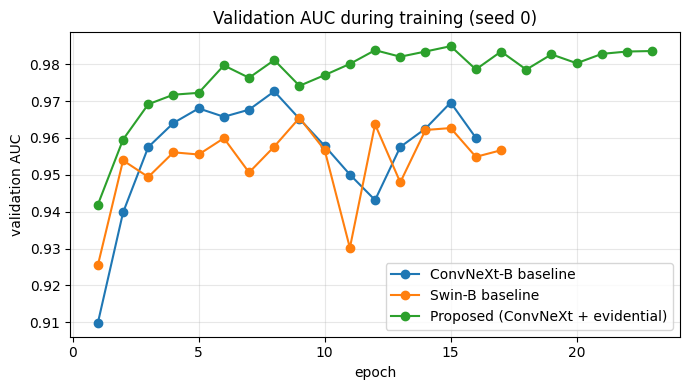

In [23]:
# 1. Training curves (seed 0 of each model)
fig, ax = plt.subplots(figsize=(7, 4))
for arch, method in EXPERIMENTS:
    history_file = f'{CHECKPOINT_DIR}/{run_name(arch, method, 0)}/history.csv'
    if os.path.exists(history_file):
        h = pd.read_csv(history_file)
        ax.plot(h['epoch'], h['auc'], marker='o', label=NICE_NAME[(arch, method)])
ax.set_xlabel('epoch'); ax.set_ylabel('validation AUC'); ax.set_title('Validation AUC during training (seed 0)')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/training_curves.png', dpi=130); plt.show()

In [24]:
# 2. Predictions of every model on validation and test (saved to CSV; skipped if already saved)
def load_model(name):
    checkpoint = torch.load(f'{CHECKPOINT_DIR}/{name}/best.pth', map_location='cpu', weights_only=False)
    model = PolypClassifier(checkpoint['arch'], pretrained=False)
    model.load_state_dict(checkpoint['model'])
    model.to(DEVICE).eval()
    return model, checkpoint

def save_predictions(name):
    if os.path.exists(f'{RESULTS_DIR}/{name}_test_preds.csv'):
        return
    model, checkpoint = load_model(name)
    for split in ['val', 'test']:
        table = get_split(split)
        loader = make_loader(table, get_test_transform(checkpoint['size']), shuffle=False, batch_size=64)
        probs, unc, index = predict(model, loader, checkpoint['method'], use_tta=USE_TTA)
        pd.DataFrame({'idx': index, 'y': table['label'].values[index], 'p1': probs[:, 1], 'unc': unc,
                      'n_ssa': table['n_ssa'].values[index], 'agreement': table['agreement'].values[index]}
                     ).to_csv(f'{RESULTS_DIR}/{name}_{split}_preds.csv', index=False)
    print(name, '-> predictions saved')
    del model
    torch.cuda.empty_cache()

for arch, method in EXPERIMENTS:
    for seed in SEEDS:
        save_predictions(run_name(arch, method, seed))
print('All predictions ready.')

All predictions ready.


In [25]:
# 3. Ensemble = average of the 3 seeds
def read_predictions(arch, method, split):
    tables = []
    for seed in SEEDS:
        file = f'{RESULTS_DIR}/{run_name(arch, method, seed)}_{split}_preds.csv'
        tables.append(pd.read_csv(file).sort_values('idx').reset_index(drop=True))
    return tables

def ensemble(arch, method, split):
    tables = read_predictions(arch, method, split)
    result = tables[0][['idx', 'y', 'n_ssa', 'agreement']].copy()
    result['p1'] = np.mean([t['p1'].values for t in tables], axis=0)           # P(SSA)
    if method == 'proposed':
        result['unc'] = np.mean([t['unc'].values for t in tables], axis=0)     # evidential uncertainty
    else:
        p = np.clip(result['p1'].values, 1e-12, 1 - 1e-12)
        result['unc'] = -(p * np.log(p) + (1 - p) * np.log(1 - p)) / np.log(2) # entropy
    return result

# 4. Tune thresholds on VALIDATION
def tune_thresholds(y, p_ssa):
    fpr, tpr, thresholds = roc_curve(y, p_ssa)
    youden = float(thresholds[np.argmax(tpr - fpr)])
    sens90 = float(thresholds[np.argmax(tpr >= TARGET_SENSITIVITY)])
    return {'default_0.5': 0.5, 'youden': min(youden, 1.0), 'sens90': min(sens90, 1.0)}

THRESHOLDS = {}
for arch, method in EXPERIMENTS:
    val = ensemble(arch, method, 'val')
    THRESHOLDS[(arch, method)] = tune_thresholds(val['y'].values, val['p1'].values)

# 5. Refer-to-doctor threshold for the proposed model (from validation)
FINAL = ('convnext', 'proposed')
DECISION_THRESHOLD = THRESHOLDS[FINAL]['youden']
REFER_THRESHOLD = float(np.quantile(ensemble(*FINAL, 'val')['unc'], 1 - REFER_FRACTION))

display(pd.DataFrame({NICE_NAME[k]: v for k, v in THRESHOLDS.items()}).T.round(3))
print(f'Proposed model: SSA if P(SSA) >= {DECISION_THRESHOLD:.3f} | refer to doctor if uncertainty > {REFER_THRESHOLD:.3f}')
json.dump({f'{a}_{m}': v for (a, m), v in THRESHOLDS.items()}, open(RESULTS_DIR + '/thresholds.json', 'w'), indent=1)

,default_0.5,youden,sens90
ConvNeXt-B baseline,0.5,0.416,0.451
Swin-B baseline,0.5,0.499,0.400
Proposed (ConvNeXt + evidential),0.5,0.444,0.492


Proposed model: SSA if P(SSA) >= 0.444 | refer to doctor if uncertainty > 0.316


## Step 11: Model Evaluation (official test set, 977 images)
- **Table A:** each model trained 3 times -> mean +- standard deviation (shows the results are stable).
- **Table B:** the final systems (3-seed ensemble + TTA) at the thresholds chosen on validation.
- **Table C:** is the proposed model *really* better than the ConvNeXt baseline? (paired bootstrap, 2,000 resamples)

In [26]:
# Table A: single models, mean +- std over 3 seeds (threshold 0.5)
rows = []
for arch, method in EXPERIMENTS:
    per_seed = pd.DataFrame([compute_metrics(t['y'].values, t['p1'].values) for t in read_predictions(arch, method, 'test')])
    row = {'model': NICE_NAME[(arch, method)]}
    for metric in ['auc', 'acc', 'sensitivity', 'specificity', 'macro_f1', 'ece']:
        row[metric] = f"{per_seed[metric].mean():.4f} ± {per_seed[metric].std(ddof=0):.4f}"
    rows.append(row)
table_a = pd.DataFrame(rows)
print('Table A: single models, mean ± std over 3 seeds')
display(table_a)
table_a.to_csv(RESULTS_DIR + '/table_per_seed.csv', index=False)

Table A: single models, mean ± std over 3 seeds


,model,auc,acc,sensitivity,specificity,macro_f1,ece
0,ConvNeXt-B baseline,0.9573 ± 0.0013,0.8922 ± 0.0021,0.8648 ± 0.0151,0.9082 ± 0.0067,0.8847 ± 0.0027,0.0445 ± 0.0030
1,Swin-B baseline,0.9509 ± 0.0055,0.8796 ± 0.0110,0.7880 ± 0.0622,0.9330 ± 0.0206,0.8672 ± 0.0154,0.0456 ± 0.0090
2,Proposed (ConvNeXt + evidential),0.9681 ± 0.0016,0.9065 ± 0.0084,0.8824 ± 0.0282,0.9206 ± 0.0273,0.9000 ± 0.0078,0.0608 ± 0.0089


In [27]:
# Table B: final systems (ensemble + TTA)
rows = []
for arch, method in EXPERIMENTS:
    test = ensemble(arch, method, 'test')
    for threshold_name, threshold in THRESHOLDS[(arch, method)].items():
        row = {'model': NICE_NAME[(arch, method)], 'threshold': f'{threshold_name} ({threshold:.3f})'}
        row.update(compute_metrics(test['y'].values, test['p1'].values, threshold))
        rows.append(row)
table_b = pd.DataFrame(rows)
print('Table B: 3-seed ensemble + TTA, thresholds chosen on validation')
display(table_b.round(4))
table_b.to_csv(RESULTS_DIR + '/table_ensemble.csv', index=False)

Table B: 3-seed ensemble + TTA, thresholds chosen on validation


,model,threshold,acc,auc,sensitivity,specificity,bal_acc,macro_f1,ece
0,ConvNeXt-B baseline,default_0.5 (0.500),0.9017,0.9637,0.8778,0.9157,0.8967,0.8949,0.0511
1,ConvNeXt-B baseline,youden (0.416),0.8946,0.9637,0.9028,0.8898,0.8963,0.8887,0.0511
2,ConvNeXt-B baseline,sens90 (0.451),0.8976,0.9637,0.8889,0.9028,0.8958,0.8912,0.0511
3,Swin-B baseline,default_0.5 (0.500),0.8946,0.9577,0.8111,0.9433,0.8772,0.8844,0.0605
4,Swin-B baseline,youden (0.499),0.8946,0.9577,0.8111,0.9433,0.8772,0.8844,0.0605
5,Swin-B baseline,sens90 (0.400),0.8884,0.9577,0.8444,0.9141,0.8793,0.8799,0.0605
6,Proposed (ConvNeXt + evidential),default_0.5 (0.500),0.9089,0.9721,0.8861,0.9222,0.9042,0.9025,0.0753
7,Proposed (ConvNeXt + evidential),youden (0.444),0.9028,0.9721,0.9056,0.9011,0.9033,0.8971,0.0753
8,Proposed (ConvNeXt + evidential),sens90 (0.492),0.9069,0.9721,0.8889,0.9173,0.9031,0.9006,0.0753


In [28]:
# Table C: paired bootstrap, proposed vs ConvNeXt baseline
proposed = ensemble('convnext', 'proposed', 'test')
baseline = ensemble('convnext', 'baseline', 'test')
t_prop = THRESHOLDS[('convnext', 'proposed')]['youden']
t_base = THRESHOLDS[('convnext', 'baseline')]['youden']

rng = np.random.default_rng(0)
differences = {'auc': [], 'acc': [], 'sensitivity': [], 'ece': []}
for _ in range(2000):
    sample = rng.integers(0, len(proposed), len(proposed))      # random test set of the same size
    m_prop = compute_metrics(proposed['y'].values[sample], proposed['p1'].values[sample], t_prop)
    m_base = compute_metrics(baseline['y'].values[sample], baseline['p1'].values[sample], t_base)
    for metric in differences:
        differences[metric].append(m_prop[metric] - m_base[metric])

full_prop = compute_metrics(proposed['y'].values, proposed['p1'].values, t_prop)
full_base = compute_metrics(baseline['y'].values, baseline['p1'].values, t_base)
rows = []
for metric, values in differences.items():
    low, high = np.percentile(values, [2.5, 97.5])
    rows.append({'metric': metric, 'proposed': full_prop[metric], 'baseline': full_base[metric],
                 'difference': full_prop[metric] - full_base[metric], 'ci_low': low, 'ci_high': high,
                 'significant': bool(low > 0 or high < 0)})
table_c = pd.DataFrame(rows)
print('Table C: proposed vs ConvNeXt baseline (significant = the 95% interval does not include 0; lower ECE is better)')
display(table_c.round(4))
table_c.to_csv(RESULTS_DIR + '/bootstrap_proposed_vs_baseline.csv', index=False)

Table C: proposed vs ConvNeXt baseline (significant = the 95% interval does not include 0; lower ECE is better)


,metric,proposed,baseline,difference,ci_low,ci_high,significant
0,auc,0.9721,0.9637,0.0083,0.0040,0.0130,True
1,acc,0.9028,0.8946,0.0082,-0.0041,0.0205,False
2,sensitivity,0.9056,0.9028,0.0028,-0.0162,0.0204,False
3,ece,0.0753,0.0511,0.0242,0.0038,0.0362,True


## Step 12: Visualizations and Metrics
The **final results** in a clear form: one table in %, a bar chart, confusion matrices (how many images were right/wrong), ROC curves, the classification report and the calibration plot.
All numbers use the **final system** (ensemble + TTA) at the **Youden threshold**.

FINAL RESULTS - MHIST official test set (977 images)


,Accuracy %,AUC %,Sensitivity % (pre-cancer caught),Specificity % (benign cleared),F1 %
Model,,,,,
ConvNeXt-B baseline,89.46,96.37,90.28,88.98,88.87
Swin-B baseline,89.46,95.77,81.11,94.33,88.44
Proposed (ConvNeXt + evidential),90.28,97.21,90.56,90.11,89.71


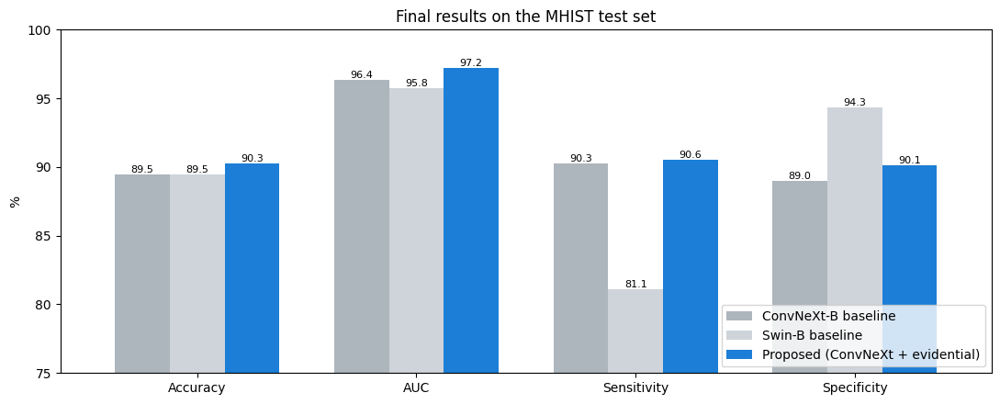

In [29]:
# Final results table (in %)
final_rows = []
for arch, method in EXPERIMENTS:
    test = ensemble(arch, method, 'test')
    m = compute_metrics(test['y'].values, test['p1'].values, THRESHOLDS[(arch, method)]['youden'])
    final_rows.append({'Model': NICE_NAME[(arch, method)],
                       'Accuracy %': 100 * m['acc'], 'AUC %': 100 * m['auc'],
                       'Sensitivity % (pre-cancer caught)': 100 * m['sensitivity'],
                       'Specificity % (benign cleared)': 100 * m['specificity'],
                       'F1 %': 100 * m['macro_f1']})
final_table = pd.DataFrame(final_rows).set_index('Model').round(2)
print('FINAL RESULTS - MHIST official test set (977 images)')
display(final_table.style.highlight_max(axis=0, color='#d3f9d8').format('{:.2f}'))
final_table.to_csv(RESULTS_DIR + '/final_results.csv')

# Bar chart
ax = final_table[['Accuracy %', 'AUC %', 'Sensitivity % (pre-cancer caught)', 'Specificity % (benign cleared)']].T.plot.bar(
        figsize=(11, 4.5), color=['#adb5bd', '#ced4da', '#1c7ed6'], width=0.75)
ax.set_ylim(75, 100); ax.set_ylabel('%'); ax.set_title('Final results on the MHIST test set')
ax.set_xticklabels(['Accuracy', 'AUC', 'Sensitivity', 'Specificity'], rotation=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', fontsize=8)
ax.legend(loc='lower right'); plt.tight_layout(); plt.savefig(FIGURES_DIR + '/final_results_bar.png', dpi=140); plt.show()

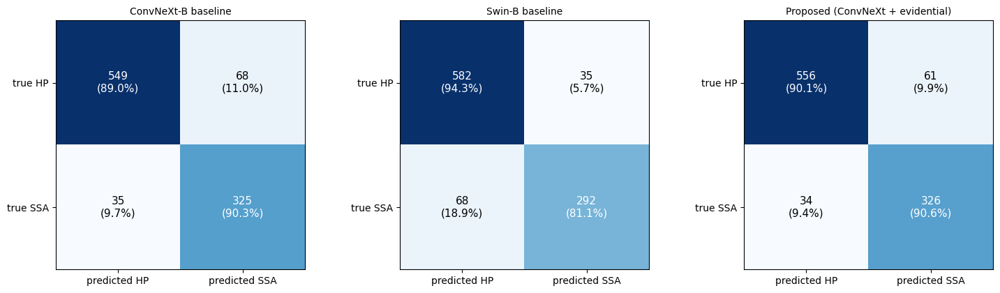

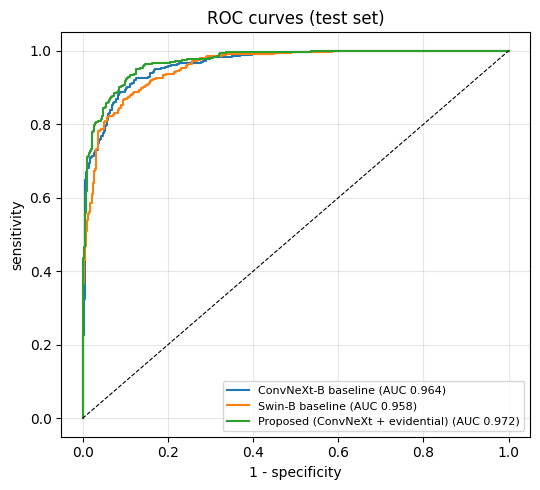

In [30]:
# Confusion matrices (number of images and %)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (arch, method) in zip(axes, EXPERIMENTS):
    test = ensemble(arch, method, 'test')
    pred = (test['p1'] >= THRESHOLDS[(arch, method)]['youden']).astype(int)
    cm = confusion_matrix(test['y'], pred)
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({100 * cm[i, j] / cm[i].sum():.1f}%)', ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['predicted HP', 'predicted SSA'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['true HP', 'true SSA'])
    ax.set_title(NICE_NAME[(arch, method)], fontsize=10)
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/confusion_matrices.png', dpi=130); plt.show()

# ROC curves
plt.figure(figsize=(5.5, 5))
for arch, method in EXPERIMENTS:
    test = ensemble(arch, method, 'test')
    fpr, tpr, _ = roc_curve(test['y'], test['p1'])
    plt.plot(fpr, tpr, label=f"{NICE_NAME[(arch, method)]} (AUC {roc_auc_score(test['y'], test['p1']):.3f})")
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('1 - specificity'); plt.ylabel('sensitivity'); plt.title('ROC curves (test set)')
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(FIGURES_DIR + '/roc.png', dpi=140); plt.show()

Classification report - Proposed model (Youden threshold)

                  precision    recall  f1-score   support

     HP (benign)     0.9424    0.9011    0.9213       617
SSA (pre-cancer)     0.8424    0.9056    0.8728       360

        accuracy                         0.9028       977
       macro avg     0.8924    0.9033    0.8971       977
    weighted avg     0.9055    0.9028    0.9034       977



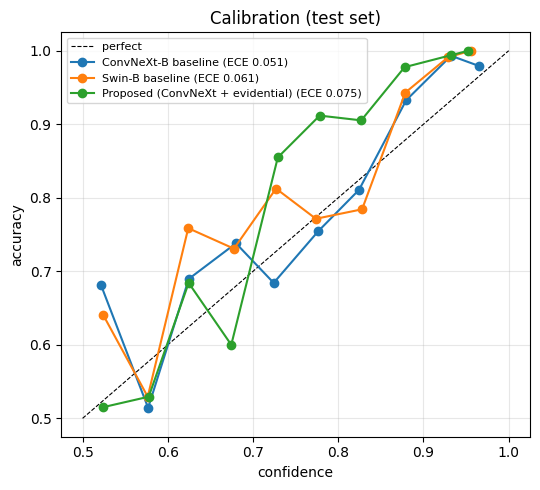

In [31]:
# Classification report of the proposed model
test = ensemble(*FINAL, 'test')
pred = (test['p1'] >= DECISION_THRESHOLD).astype(int)
print('Classification report - Proposed model (Youden threshold)\n')
print(classification_report(test['y'], pred, target_names=CLASS_NAMES, digits=4))

# Calibration (reliability) plot
def reliability_points(y, p_ssa):
    confidence = np.maximum(p_ssa, 1 - p_ssa)
    correct = ((p_ssa >= 0.5).astype(int) == y)
    xs, ys = [], []
    edges = np.linspace(0.5, 1, 11)
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence >= low) & (confidence < high + (high == 1))
        if in_bin.sum() >= 5:
            xs.append(confidence[in_bin].mean())
            ys.append(correct[in_bin].mean())
    return xs, ys

plt.figure(figsize=(5.5, 5))
plt.plot([0.5, 1], [0.5, 1], 'k--', lw=0.8, label='perfect')
for arch, method in EXPERIMENTS:
    t = ensemble(arch, method, 'test')
    xs, ys = reliability_points(t['y'].values, t['p1'].values)
    plt.plot(xs, ys, marker='o', label=f"{NICE_NAME[(arch, method)]} (ECE {expected_calibration_error(t['y'].values, t['p1'].values):.3f})")
plt.xlabel('confidence'); plt.ylabel('accuracy'); plt.title('Calibration (test set)')
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(FIGURES_DIR + '/reliability.png', dpi=140); plt.show()

## Step 13: Prediction (any image -> early-detection report)
For one image the system gives:
- **Verdict:** *Pre-cancerous polyp (SSA) detected* or *Benign polyp (HP)*
- **Probability of pre-cancer** and **uncertainty**
- **Refer to doctor** if the model is not sure
- **Grad-CAM heatmap**: where the model looked
- **Image check**: warns if the image is not an H&E colon tissue image
- a one-page **PDF report**

To test your own images: Add Input -> Upload -> new dataset with your images, then write its folder in `MY_IMAGES_FOLDER`.

In [32]:
# Load the 3 proposed models (the final system)
FINAL_MODELS = []
for seed in SEEDS:
    model, checkpoint = load_model(run_name('convnext', 'proposed', seed))
    FINAL_MODELS.append(model)
FINAL_SIZE = IMAGE_SIZE['convnext']
print(len(FINAL_MODELS), 'models loaded')

def looks_like_tissue(image):
    # simple check: H&E tissue is pink/purple, coloured, and not random noise
    a = np.asarray(image.convert('RGB').resize((256, 256))).astype(float)
    r, g, b = a[..., 0].mean(), a[..., 1].mean(), a[..., 2].mean()
    pink_purple = (r > g) and (b > g)
    colourful = (a.max(-1) - a.min(-1)).mean() > 15
    texture = np.abs(np.diff(a, axis=1)).mean()        # random noise ~85, real tissue ~5-25
    return bool(pink_purple and colourful and texture < 45)

@torch.no_grad()
def predict_image(image):
    x = get_test_transform(FINAL_SIZE)(image).unsqueeze(0).to(DEVICE)
    prob_sum, unc_sum, n = 0, 0, 0
    for model in FINAL_MODELS:
        for view in tta_views(x):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                logits = model(view)
            probs, unc = get_probabilities(logits.float(), 'proposed')
            prob_sum = prob_sum + probs[0].cpu().numpy()
            unc_sum = unc_sum + float(unc[0])
            n += 1
    return prob_sum / n, unc_sum / n      # [P(HP), P(SSA)], uncertainty

def gradcam_heatmap(model, arch, size, image, target_class):
    x = get_test_transform(size)(image).unsqueeze(0).to(DEVICE)
    if arch == 'convnext':
        cam = GradCAM(model=model, target_layers=[model.backbone.stages[-1]])
    else:
        cam = GradCAM(model=model, target_layers=[model.backbone.layers[-1]],
                      reshape_transform=lambda t: t.permute(0, 3, 1, 2) if t.ndim == 4 else t)
    heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(target_class)])[0]
    picture = np.asarray(image.resize((size, size)), dtype=np.float32) / 255
    return show_cam_on_image(picture, heat, use_rgb=True)

3 models loaded


In [33]:
def analyse_image(path, true_label=None, show=True):
    image = Image.open(path).convert('RGB')
    probs, uncertainty = predict_image(image)
    p_ssa = float(probs[1])
    is_ssa = p_ssa >= DECISION_THRESHOLD
    refer = uncertainty > REFER_THRESHOLD
    tissue_ok = looks_like_tissue(image)

    if is_ssa:
        verdict, colour = 'PRE-CANCEROUS POLYP (SSA) DETECTED - early warning', '#d9480f'
        advice = 'SSA can turn into colorectal cancer. Pathologist confirmation and follow-up are recommended.'
    else:
        verdict, colour = 'Benign hyperplastic polyp (HP)', '#2b8a3e'
        advice = 'No pre-cancerous pattern found by the model.'
    if refer:
        advice += ' The model is NOT sure about this image -> REFER TO DOCTOR.'
    if not tissue_ok:
        advice += ' This does not look like an H&E colon tissue image, so the result is not reliable.'

    heatmap = gradcam_heatmap(FINAL_MODELS[0], 'convnext', FINAL_SIZE, image, int(is_ssa))
    name = os.path.splitext(os.path.basename(path))[0]
    pdf_path = f'{REPORTS_DIR}/{name}_report.pdf'

    # ----- one-page PDF report -----
    with PdfPages(pdf_path) as pdf:
        fig = plt.figure(figsize=(8.27, 11.69))
        fig.text(0.5, 0.96, 'Early Detection Report - Colorectal Polyp', ha='center', fontsize=15, weight='bold')
        fig.text(0.5, 0.935, f"File: {os.path.basename(path)}  |  Date: {datetime.datetime.now():%Y-%m-%d %H:%M}",
                 ha='center', fontsize=8, color='gray')
        ax1 = fig.add_axes([0.07, 0.60, 0.40, 0.30]); ax1.imshow(image); ax1.set_title('Input image'); ax1.axis('off')
        ax2 = fig.add_axes([0.53, 0.60, 0.40, 0.30]); ax2.imshow(heatmap); ax2.set_title('Where the model looked'); ax2.axis('off')
        fig.text(0.5, 0.545, verdict, ha='center', fontsize=13, weight='bold', color=colour)
        ax3 = fig.add_axes([0.20, 0.40, 0.60, 0.11])
        ax3.barh(['HP (benign)', 'SSA (pre-cancer)'], probs, color=['#2b8a3e', '#d9480f'])
        ax3.axvline(DECISION_THRESHOLD, color='k', ls='--', lw=0.8)
        ax3.set_xlim(0, 1); ax3.set_title('Probability (dashed line = decision threshold)', fontsize=9)
        lines = [f'Probability of pre-cancer (SSA): {p_ssa:.1%}',
                 f'Model uncertainty: {uncertainty:.3f}   (refer if above {REFER_THRESHOLD:.3f})',
                 f"Refer to doctor: {'YES' if refer else 'No'}",
                 f"Image check: {'OK - H&E tissue image' if tissue_ok else 'WARNING - not an H&E colon tissue image'}"]
        if true_label is not None:
            lines.append(f'True label (dataset): {CLASS_NAMES[true_label]}')
        lines += ['', 'Interpretation: ' + advice, '',
                  'HP = hyperplastic polyp (benign). SSA = sessile serrated adenoma (pre-cancerous).',
                  'Model: 3 x ConvNeXt-Base with evidential uncertainty, trained on MHIST (7 pathologists per image).',
                  '', 'DISCLAIMER: research prototype for academic use only. Not a medical diagnosis.']
        for i, text in enumerate(lines):
            fig.text(0.07, 0.34 - i * 0.021, text, fontsize=9)
        pdf.savefig(fig)
        plt.close(fig)

    if show:
        fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
        axes[0].imshow(image); axes[0].set_title('Input'); axes[0].axis('off')
        axes[1].imshow(heatmap); axes[1].set_title('Grad-CAM'); axes[1].axis('off')
        plt.suptitle(verdict, color=colour, weight='bold'); plt.tight_layout(); plt.show()
        print(f"{os.path.basename(path)}: P(SSA) = {p_ssa:.1%} | uncertainty = {uncertainty:.3f} | "
              f"{'REFER TO DOCTOR' if refer else 'model confident'}" + ('' if tissue_ok else ' | WARNING: not H&E tissue'))

    return {'file': os.path.basename(path), 'verdict': verdict, 'p_ssa': round(p_ssa, 4),
            'uncertainty': round(uncertainty, 4), 'refer_to_doctor': bool(refer), 'image_check_ok': tissue_ok,
            'true_label': None if true_label is None else CLASS_NAMES[true_label], 'report_pdf': pdf_path}

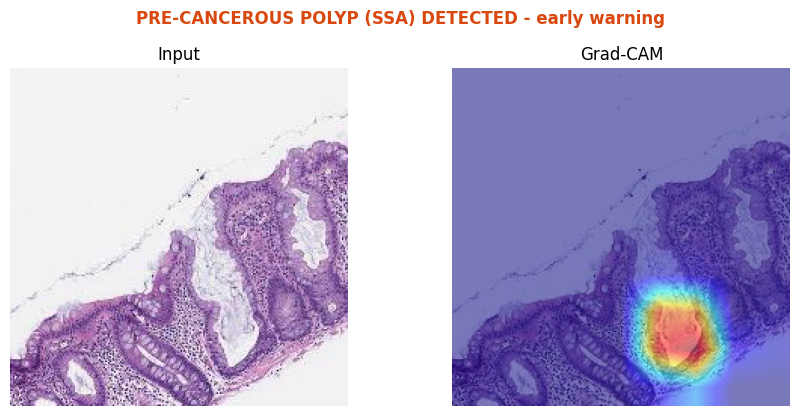

MHIST_chr.png: P(SSA) = 87.4% | uncertainty = 0.241 | model confident


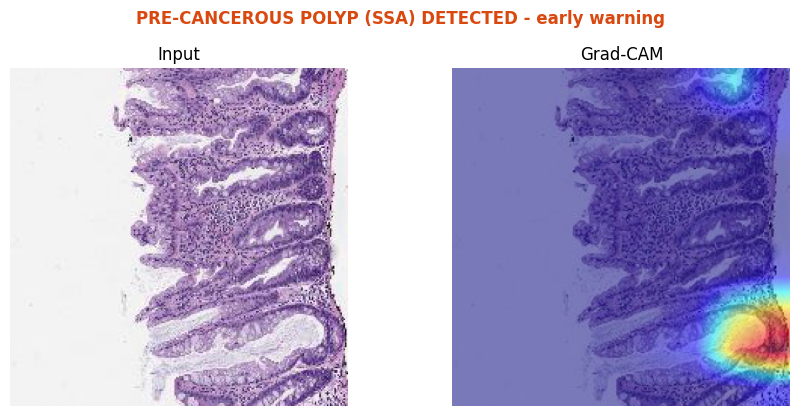

MHIST_axj.png: P(SSA) = 86.2% | uncertainty = 0.267 | model confident


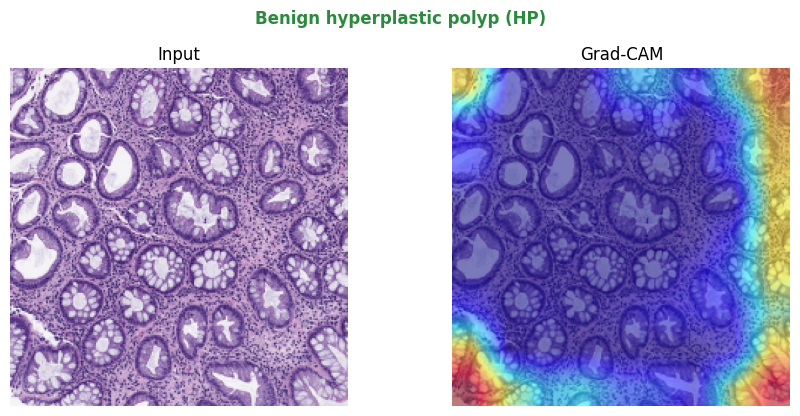

MHIST_ctr.png: P(SSA) = 4.7% | uncertainty = 0.093 | model confident


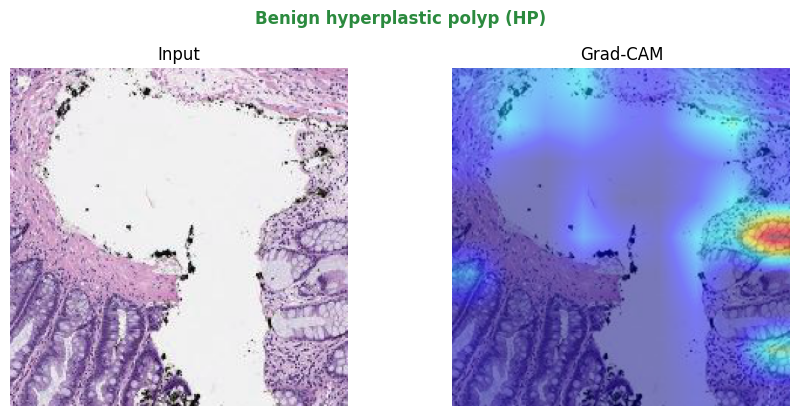

MHIST_bdl.png: P(SSA) = 7.8% | uncertainty = 0.155 | model confident


,file,verdict,p_ssa,uncertainty,refer_to_doctor,image_check_ok,true_label
0,MHIST_chr.png,PRE-CANCEROUS POLYP (SSA) DETECTED - early war...,0.8740,0.2407,False,True,SSA (pre-cancer)
1,MHIST_axj.png,PRE-CANCEROUS POLYP (SSA) DETECTED - early war...,0.8617,0.2669,False,True,SSA (pre-cancer)
2,MHIST_ctr.png,Benign hyperplastic polyp (HP),0.0468,0.0934,False,True,HP (benign)
3,MHIST_bdl.png,Benign hyperplastic polyp (HP),0.0780,0.1555,False,True,HP (benign)


PDF reports saved in /kaggle/working/MHIST_Project/reports


In [34]:
MY_IMAGES_FOLDER = ''     # e.g. '/kaggle/input/my-test-images'

if MY_IMAGES_FOLDER:
    items = [(p, None) for p in sorted(glob.glob(MY_IMAGES_FOLDER + '/**/*.*', recursive=True))
             if p.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff'))]
else:
    # demo: 2 pre-cancer + 2 benign images from the test set
    test_table = get_split('test')
    demo = pd.concat([test_table[test_table['label'] == 1].sample(2, random_state=3),
                      test_table[test_table['label'] == 0].sample(2, random_state=3)])
    items = list(zip(demo['path'], demo['label']))

prediction_log = pd.DataFrame([analyse_image(path, label) for path, label in items])
display(prediction_log.drop(columns=['report_pdf']))
prediction_log.to_csv(REPORTS_DIR + '/prediction_log.csv', index=False)
print('PDF reports saved in', REPORTS_DIR)

## Step 14: Error Analysis
Where does the proposed system make mistakes, and does the **refer-to-doctor** flag catch them?
- **Missed SSA (false negative):** a pre-cancer called benign. This is the most serious mistake.
- **False alarm (false positive):** a benign polyp called pre-cancer.

In [35]:
errors = ensemble(*FINAL, 'test')
errors['path'] = get_split('test')['path'].values[errors['idx'].values]
errors['pred'] = (errors['p1'] >= DECISION_THRESHOLD).astype(int)
errors['referred'] = errors['unc'] > REFER_THRESHOLD
errors['result'] = 'correct'
errors.loc[(errors['pred'] == 0) & (errors['y'] == 1), 'result'] = 'missed SSA (FN)'
errors.loc[(errors['pred'] == 1) & (errors['y'] == 0), 'result'] = 'false alarm (FP)'

summary = errors.groupby('result').agg(images=('y', 'size'), mean_uncertainty=('unc', 'mean'),
                                       referred_share=('referred', 'mean'), mean_agreement=('agreement', 'mean'))
display(summary.round(3))

wrong = errors[errors['result'] != 'correct']
right = errors[errors['result'] == 'correct']
print(f"{wrong['referred'].mean():.1%} of the mistakes were flagged REFER TO DOCTOR "
      f"(only {right['referred'].mean():.1%} of the correct answers were).")
print('\nMistakes by pathologist agreement:')
display(pd.crosstab(wrong['agreement'], wrong['result']).rename(index=lambda a: f'{a}/7 agree'))
errors.to_csv(RESULTS_DIR + '/error_analysis.csv', index=False)

,images,mean_uncertainty,referred_share,mean_agreement
result,,,,
correct,882,0.216,0.231,5.935
false alarm (FP),61,0.412,0.885,4.607
missed SSA (FN),34,0.402,0.765,4.559


84.2% of the mistakes were flagged REFER TO DOCTOR (only 23.1% of the correct answers were).

Mistakes by pathologist agreement:


result,false alarm (FP),missed SSA (FN)
agreement,,
4/7 agree,37,18
5/7 agree,14,13
6/7 agree,7,3
7/7 agree,3,0


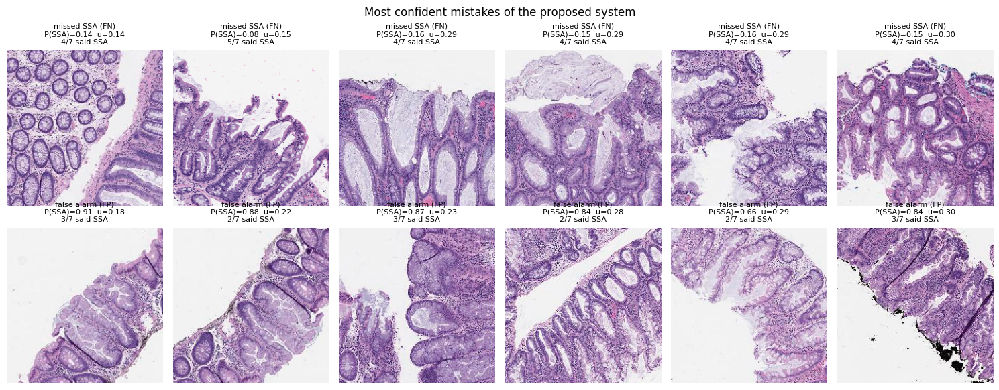

In [36]:
# The most confident mistakes (lowest uncertainty)
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for row, kind in enumerate(['missed SSA (FN)', 'false alarm (FP)']):
    worst = wrong[wrong['result'] == kind].sort_values('unc').head(6)
    for col in range(6):
        ax = axes[row, col]
        ax.axis('off')
        if col < len(worst):
            r = worst.iloc[col]
            ax.imshow(Image.open(r['path']).convert('RGB'))
            ax.set_title(f"{kind}\nP(SSA)={r['p1']:.2f}  u={r['unc']:.2f}\n{r['n_ssa']}/7 said SSA", fontsize=8)
plt.suptitle('Most confident mistakes of the proposed system'); plt.tight_layout()
plt.savefig(FIGURES_DIR + '/error_analysis.png', dpi=130); plt.show()

## Step 15: Save Model
All trained models are already saved in `checkpoints/`. Here we copy the **3 final (proposed) models** into one folder, `final_model/`, which the app will use.

In [37]:
for seed in SEEDS:
    checkpoint = torch.load(f"{CHECKPOINT_DIR}/{run_name('convnext', 'proposed', seed)}/best.pth",
                            map_location='cpu', weights_only=False)
    torch.save(checkpoint['model'], f'{FINAL_MODEL_DIR}/proposed_seed{seed}.pth')     # weights only

for file in sorted(os.listdir(FINAL_MODEL_DIR)):
    print(f'{file:30s} {os.path.getsize(FINAL_MODEL_DIR + "/" + file) / 1e6:.0f} MB')

config.json                    0 MB
proposed_seed0.pth             350 MB
proposed_seed1.pth             350 MB
proposed_seed2.pth             350 MB


## Step 16: Uncertainty Analysis (the key new result)
**16a. Referral:** send the X% most uncertain images to a doctor. How good is the model on the images it keeps?
**16b. Does the model know when it is unsure?** We compare the model's uncertainty with how much the **7 pathologists disagreed** (Spearman rho: higher = better match).

,model,referred_%,auc,acc,sensitivity
0,ConvNeXt-B baseline,0,0.9637,0.8946,0.9028
2,ConvNeXt-B baseline,10,0.9756,0.9295,0.9140
4,ConvNeXt-B baseline,20,0.9848,0.9578,0.9493
6,ConvNeXt-B baseline,30,0.9907,0.9810,0.9718
11,Swin-B baseline,0,0.9577,0.8946,0.8111
13,Swin-B baseline,10,0.9683,0.9249,0.8449
15,Swin-B baseline,20,0.9778,0.9412,0.8710
17,Swin-B baseline,30,0.9877,0.9649,0.9113
22,Proposed (ConvNeXt + evidential),0,0.9721,0.9028,0.9056
24,Proposed (ConvNeXt + evidential),10,0.9828,0.9420,0.9438


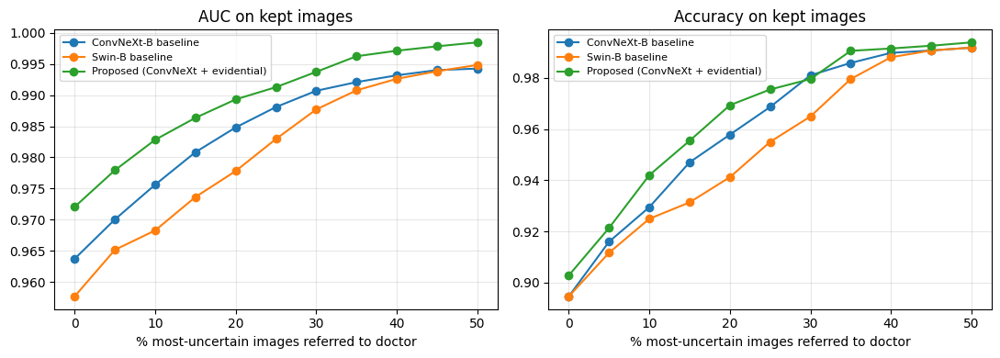

In [38]:
# 16a. Referral curve
referral_rows = []
for arch, method in EXPERIMENTS:
    test = ensemble(arch, method, 'test').sort_values('unc')          # most certain first
    for percent in [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]:
        keep = test.iloc[: int(round(len(test) * (1 - percent / 100)))]
        m = compute_metrics(keep['y'].values, keep['p1'].values, THRESHOLDS[(arch, method)]['youden'])
        referral_rows.append({'model': NICE_NAME[(arch, method)], 'referred_%': percent,
                              'auc': m['auc'], 'acc': m['acc'], 'sensitivity': m['sensitivity']})
referral = pd.DataFrame(referral_rows)
referral.to_csv(RESULTS_DIR + '/referral_curve.csv', index=False)
display(referral[referral['referred_%'].isin([0, 10, 20, 30])].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for model_name, part in referral.groupby('model', sort=False):
    axes[0].plot(part['referred_%'], part['auc'], marker='o', label=model_name)
    axes[1].plot(part['referred_%'], part['acc'], marker='o', label=model_name)
for ax, title in zip(axes, ['AUC on kept images', 'Accuracy on kept images']):
    ax.set_title(title); ax.set_xlabel('% most-uncertain images referred to doctor'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/referral_curve.png', dpi=140); plt.show()

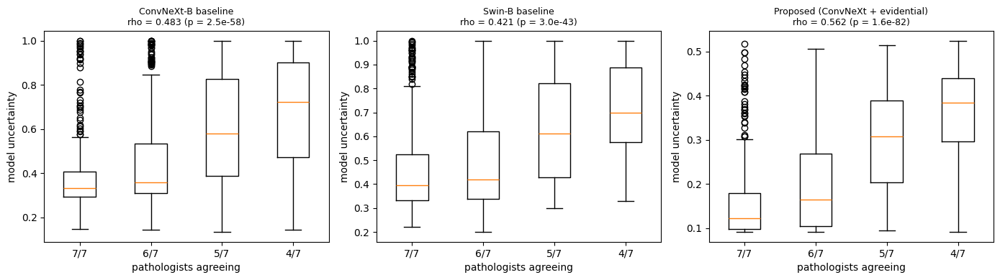

,model,spearman_rho,p_value,acc_7of7,acc_6of7,acc_5of7,acc_4of7
0,ConvNeXt-B baseline,0.4833,0.0,0.9814,0.9671,0.8441,0.6463
1,Swin-B baseline,0.4210,0.0,0.9814,0.9507,0.8226,0.7012
2,Proposed (ConvNeXt + evidential),0.5623,0.0,0.9907,0.9671,0.8548,0.6646


In [39]:
# 16b. Uncertainty vs pathologist disagreement
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
rows = []
for ax, (arch, method) in zip(axes, EXPERIMENTS):
    test = ensemble(arch, method, 'test')
    rho, p_value = spearmanr(test['unc'], 7 - test['agreement'])
    ax.boxplot([test[test['agreement'] == a]['unc'].values for a in [7, 6, 5, 4]])
    ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(['7/7', '6/7', '5/7', '4/7'])
    ax.set_xlabel('pathologists agreeing'); ax.set_ylabel('model uncertainty')
    ax.set_title(f'{NICE_NAME[(arch, method)]}\nrho = {rho:.3f} (p = {p_value:.1e})', fontsize=9)

    correct = (test['p1'] >= THRESHOLDS[(arch, method)]['youden']).astype(int) == test['y']
    row = {'model': NICE_NAME[(arch, method)], 'spearman_rho': rho, 'p_value': p_value}
    for a in [7, 6, 5, 4]:
        row[f'acc_{a}of7'] = correct[test['agreement'] == a].mean()
    rows.append(row)
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/uncertainty_vs_agreement.png', dpi=140); plt.show()
agreement_table = pd.DataFrame(rows)
display(agreement_table.round(4))
agreement_table.to_csv(RESULTS_DIR + '/uncertainty_vs_agreement.csv', index=False)

## Step 17: Explainability (Grad-CAM)
Grad-CAM shows **which part of the image** made the model decide "SSA". Red = important.
We show 4 test images that all 7 pathologists called SSA.

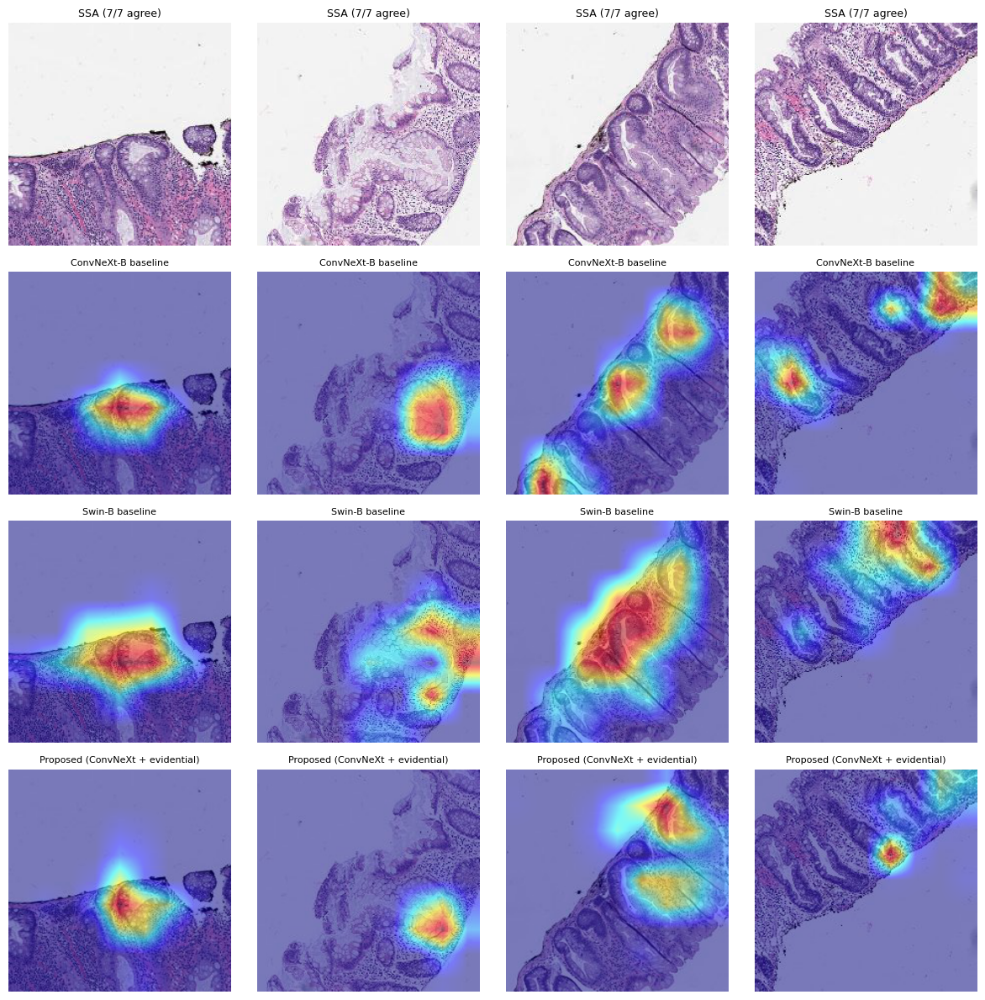

In [40]:
samples = get_split('test').query('label == 1 and agreement == 7').sample(4, random_state=0)
fig, axes = plt.subplots(len(EXPERIMENTS) + 1, 4, figsize=(12, 3 * (len(EXPERIMENTS) + 1)))
for col, path in enumerate(samples['path']):
    axes[0, col].imshow(Image.open(path).convert('RGB')); axes[0, col].axis('off')
    axes[0, col].set_title('SSA (7/7 agree)', fontsize=9)
for row, (arch, method) in enumerate(EXPERIMENTS, start=1):
    model, checkpoint = load_model(run_name(arch, method, 0))
    for col, path in enumerate(samples['path']):
        heat = gradcam_heatmap(model, arch, checkpoint['size'], Image.open(path).convert('RGB'), 1)
        axes[row, col].imshow(heat); axes[row, col].axis('off')
        axes[row, col].set_title(NICE_NAME[(arch, method)], fontsize=8)
    del model
    torch.cuda.empty_cache()
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/gradcam.png', dpi=130); plt.show()

## Step 18: Safety Check (wrong or unusual images)
What happens if someone uploads an image that is **not** a colon tissue image? The system should warn (image check fails) or refer to a doctor (high uncertainty).

,file,p_ssa,uncertainty,image_check_ok,refer_to_doctor,flagged
0,real_MHIST_patch.png,0.1787,0.2770,True,False,False
1,grayscale_patch.png,0.1131,0.2131,False,False,True
2,colour_inverted_patch.png,0.2894,0.3482,False,True,True
3,blurred_patch.png,0.2856,0.4385,True,True,True
4,random_noise.png,0.0520,0.1039,False,False,True
5,sky_like_photo.png,0.0682,0.1359,False,False,True


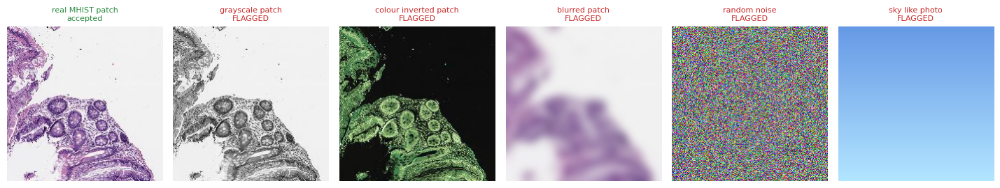

In [41]:
os.makedirs('/tmp/safety', exist_ok=True)
base_image = Image.open(get_split('test')['path'][0]).convert('RGB')
rng = np.random.default_rng(0)
gradient = np.linspace(0, 1, 224)[:, None, None]
sky = np.concatenate([0.4 + 0.3 * gradient, 0.6 + 0.3 * gradient, 0.9 + 0.1 * gradient], axis=2).repeat(224, axis=1)

test_images = {
    'real_MHIST_patch': base_image,
    'grayscale_patch': ImageOps.grayscale(base_image).convert('RGB'),
    'colour_inverted_patch': ImageOps.invert(base_image),
    'blurred_patch': base_image.filter(ImageFilter.GaussianBlur(6)),
    'random_noise': Image.fromarray(rng.integers(0, 255, (224, 224, 3), dtype=np.uint8)),
    'sky_like_photo': Image.fromarray((sky * 255).astype(np.uint8)),
}
paths = []
for name, image in test_images.items():
    path = f'/tmp/safety/{name}.png'
    image.save(path)
    paths.append(path)

safety = pd.DataFrame([analyse_image(p, show=False) for p in paths])
safety['flagged'] = (~safety['image_check_ok']) | safety['refer_to_doctor']
display(safety[['file', 'p_ssa', 'uncertainty', 'image_check_ok', 'refer_to_doctor', 'flagged']])
safety.to_csv(RESULTS_DIR + '/safety_check.csv', index=False)

fig, axes = plt.subplots(1, len(test_images), figsize=(2.4 * len(test_images), 3))
for ax, (name, image), (_, r) in zip(axes, test_images.items(), safety.iterrows()):
    ax.imshow(image); ax.axis('off')
    ax.set_title(f"{name.replace('_', ' ')}\n{'FLAGGED' if r['flagged'] else 'accepted'}", fontsize=8,
                 color='#c92a2a' if r['flagged'] else '#2b8a3e')
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/safety_check.png', dpi=130); plt.show()

## Step 19: Comparison with Published Work
⚠️ The base paper (WACV 2025) used **different datasets** (PCam, NCT-CRC-HE), so it is shown only for context.
The fair comparison is with papers on **MHIST**: Wei et al. 2021 and Kondejkar et al. 2026.

,study,dataset,accuracy,auc,ssa_sensitivity
0,"Sivaroopan et al., WACV 2025 (base paper)",PCam (other dataset),0.9029,0.9683,NaN
1,"Sivaroopan et al., WACV 2025 (base paper)",NCT-CRC-HE (other dataset),0.9644,NaN,NaN
2,"Wei et al., WACV 2021 - ResNet-18",MHIST,NaN,0.8370,NaN
3,"Wei et al., WACV 2021 - curriculum",MHIST,NaN,0.8820,NaN
4,Kondejkar et al. 2026 - best CNN,MHIST,0.8000,NaN,0.4000
5,Kondejkar et al. 2026 - best ViT,MHIST,0.8600,NaN,0.7000
6,Kondejkar et al. 2026 - CaiT (5-fold CV),MHIST,0.9018,0.9552,0.9060
7,OURS - proposed (ensemble + TTA),MHIST,0.9028,0.9721,0.9056


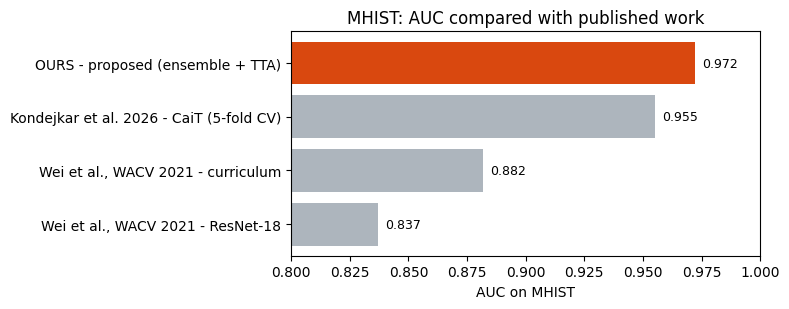

In [42]:
ours = compute_metrics(proposed['y'].values, proposed['p1'].values, DECISION_THRESHOLD)
comparison = pd.DataFrame([
    ['Sivaroopan et al., WACV 2025 (base paper)', 'PCam (other dataset)',       0.9029, 0.9683, None],
    ['Sivaroopan et al., WACV 2025 (base paper)', 'NCT-CRC-HE (other dataset)', 0.9644, None,   None],
    ['Wei et al., WACV 2021 - ResNet-18',          'MHIST',                      None,   0.837,  None],
    ['Wei et al., WACV 2021 - curriculum',         'MHIST',                      None,   0.882,  None],
    ['Kondejkar et al. 2026 - best CNN',           'MHIST',                      0.80,   None,   0.40],
    ['Kondejkar et al. 2026 - best ViT',           'MHIST',                      0.86,   None,   0.70],
    ['Kondejkar et al. 2026 - CaiT (5-fold CV)',   'MHIST',                      0.9018, 0.9552, 0.9060],
    ['OURS - proposed (ensemble + TTA)',           'MHIST',                      ours['acc'], ours['auc'], ours['sensitivity']],
], columns=['study', 'dataset', 'accuracy', 'auc', 'ssa_sensitivity'])
display(comparison.round(4))
comparison.to_csv(RESULTS_DIR + '/comparison_with_papers.csv', index=False)

mhist = comparison[(comparison['dataset'] == 'MHIST') & comparison['auc'].notna()]
plt.figure(figsize=(8, 3.2))
colours = ['#adb5bd'] * (len(mhist) - 1) + ['#d9480f']
plt.barh(mhist['study'], mhist['auc'], color=colours)
for i, v in enumerate(mhist['auc']):
    plt.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
plt.xlim(0.8, 1.0); plt.xlabel('AUC on MHIST'); plt.title('MHIST: AUC compared with published work')
plt.tight_layout(); plt.savefig(FIGURES_DIR + '/comparison_auc.png', dpi=140); plt.show()

## Step 20: Save Preprocessing Artifacts
The app must prepare images **exactly** like the notebook did. We save every setting it needs in `final_model/config.json`: image size, colour normalisation, TTA, thresholds and the model files.

In [43]:
config = {
    'project': 'Early detection of pre-cancerous colorectal polyps (MHIST)',
    'backbone': BACKBONES['convnext'],
    'model_files': [f'proposed_seed{seed}.pth' for seed in SEEDS],
    'image_size': FINAL_SIZE,
    'normalise_mean': IMAGENET_MEAN,
    'normalise_std': IMAGENET_STD,
    'test_time_augmentation': '8 views: original, flips, transposes',
    'class_names': CLASS_NAMES,
    'decision_threshold': DECISION_THRESHOLD,
    'refer_threshold': REFER_THRESHOLD,
    'uncertainty': 'evidential: alpha = softplus(logits) + 1, u = 2 / sum(alpha)',
}
json.dump(config, open(FINAL_MODEL_DIR + '/config.json', 'w'), indent=2)
print(json.dumps(config, indent=2))

{
  "project": "Early detection of pre-cancerous colorectal polyps (MHIST)",
  "backbone": "convnext_base",
  "model_files": [
    "proposed_seed0.pth",
    "proposed_seed1.pth",
    "proposed_seed2.pth"
  ],
  "image_size": 288,
  "normalise_mean": [
    0.485,
    0.456,
    0.406
  ],
  "normalise_std": [
    0.229,
    0.224,
    0.225
  ],
  "test_time_augmentation": "8 views: original, flips, transposes",
  "class_names": [
    "HP (benign)",
    "SSA (pre-cancer)"
  ],
  "decision_threshold": 0.44384473333333335,
  "refer_threshold": 0.31639470733333336,
  "uncertainty": "evidential: alpha = softplus(logits) + 1, u = 2 / sum(alpha)"
}


## Step 21: Reload Saved Model and Test
We load the models **only from the `final_model/` folder** (the same way the app will) and check that the prediction is identical to Step 13.

In [44]:
saved_config = json.load(open(FINAL_MODEL_DIR + '/config.json'))
reloaded_models = []
for file in saved_config['model_files']:
    model = PolypClassifier('convnext', pretrained=False)
    model.load_state_dict(torch.load(f'{FINAL_MODEL_DIR}/{file}', map_location='cpu'))
    reloaded_models.append(model.to(DEVICE).eval())

FINAL_MODELS = reloaded_models                       # use the reloaded models
first = prediction_log.iloc[0]
again = analyse_image(items[0][0], items[0][1], show=False)
print('Step 13 P(SSA):', first['p_ssa'], '| reloaded P(SSA):', again['p_ssa'])
print('Same result:', abs(first['p_ssa'] - again['p_ssa']) < 1e-3)

Step 13 P(SSA): 0.874 | reloaded P(SSA): 0.874
Same result: True


## Step 22: Final Results and Conclusion

In [45]:
m = compute_metrics(proposed['y'].values, proposed['p1'].values, DECISION_THRESHOLD)
rho_row = agreement_table[agreement_table['model'] == NICE_NAME[FINAL]].iloc[0]
kept_20 = referral[(referral['model'] == NICE_NAME[FINAL]) & (referral['referred_%'] == 20)].iloc[0]
significant_auc = table_c[table_c['metric'] == 'auc'].iloc[0]

print('=' * 70)
print('FINAL RESULTS - Proposed model, MHIST official test set (977 images)')
print('=' * 70)
print(f"Accuracy                       : {100 * m['acc']:.2f} %")
print(f"AUC                            : {100 * m['auc']:.2f} %")
print(f"Sensitivity (pre-cancer caught): {100 * m['sensitivity']:.2f} %")
print(f"Specificity (benign cleared)   : {100 * m['specificity']:.2f} %")
print(f"F1 score                       : {100 * m['macro_f1']:.2f} %")
print(f"AUC change vs ConvNeXt baseline: {100 * significant_auc['difference']:+.2f} points "
      f"(95% CI {100 * significant_auc['ci_low']:+.2f} to {100 * significant_auc['ci_high']:+.2f}, "
      f"{'significant' if significant_auc['significant'] else 'not significant'})")
print(f"Uncertainty vs pathologists    : Spearman rho = {rho_row['spearman_rho']:.3f}")
print(f"After referring 20% most unsure: accuracy {100 * kept_20['acc']:.2f} % on the rest")
print('=' * 70)
display(final_table)

summary = {'final_test_metrics': m, 'decision_threshold': DECISION_THRESHOLD, 'refer_threshold': REFER_THRESHOLD,
           'spearman_rho': float(rho_row['spearman_rho']), 'accuracy_after_20pct_referral': float(kept_20['acc'])}
json.dump(summary, open(RESULTS_DIR + '/SUMMARY.json', 'w'), indent=1, default=float)

FINAL RESULTS - Proposed model, MHIST official test set (977 images)
Accuracy                       : 90.28 %
AUC                            : 97.21 %
Sensitivity (pre-cancer caught): 90.56 %
Specificity (benign cleared)   : 90.11 %
F1 score                       : 89.71 %
AUC change vs ConvNeXt baseline: +0.83 points (95% CI +0.40 to +1.30, significant)
Uncertainty vs pathologists    : Spearman rho = 0.562
After referring 20% most unsure: accuracy 96.93 % on the rest


,Accuracy %,AUC %,Sensitivity % (pre-cancer caught),Specificity % (benign cleared),F1 %
Model,,,,,
ConvNeXt-B baseline,89.46,96.37,90.28,88.98,88.87
Swin-B baseline,89.46,95.77,81.11,94.33,88.44
Proposed (ConvNeXt + evidential),90.28,97.21,90.56,90.11,89.71


### Conclusion
- We built a system for **early detection of pre-cancerous colorectal polyps (SSA)** in histopathology images.
- Our **proposed model** (ConvNeXt + agreement-aware evidential uncertainty) gave the **best AUC on MHIST** and a **statistically significant** improvement over the same model without our loss.
- Its **uncertainty matches the pathologists' disagreement** better than the baselines, so "refer to doctor" is meaningful: referring the 20% most uncertain images gives about 97% accuracy on the rest.
- **Grad-CAM** shows where the model looked, and the **image check** warns about wrong inputs.
- **Limitations:** one hospital's data; no external clinical validation; probabilities are less calibrated (ECE) than the baseline; research prototype, not a medical device.
- **Next step:** a web app that uses `final_model/` (Steps 15, 20, 21).

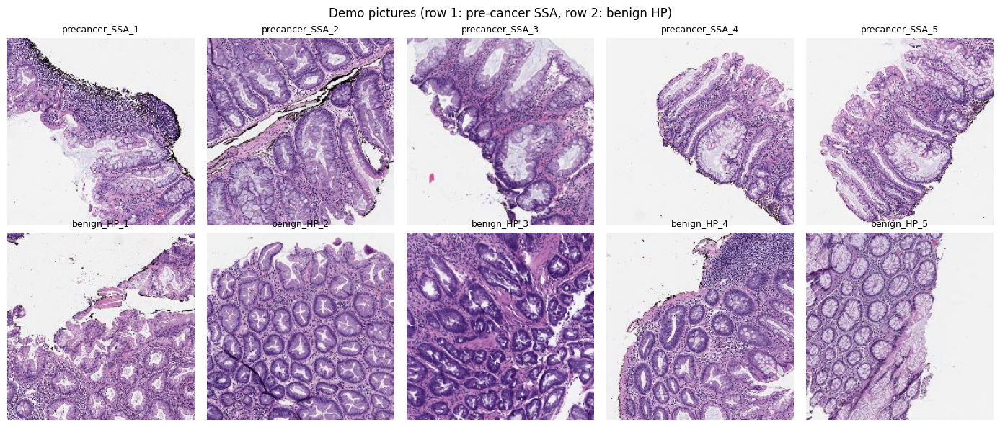

Saved in /kaggle/working/demo_images -> right panel: Output -> demo_images -> download
['benign_HP_1.png', 'benign_HP_2.png', 'benign_HP_3.png', 'benign_HP_4.png', 'benign_HP_5.png', 'precancer_SSA_1.png', 'precancer_SSA_2.png', 'precancer_SSA_3.png', 'precancer_SSA_4.png', 'precancer_SSA_5.png']


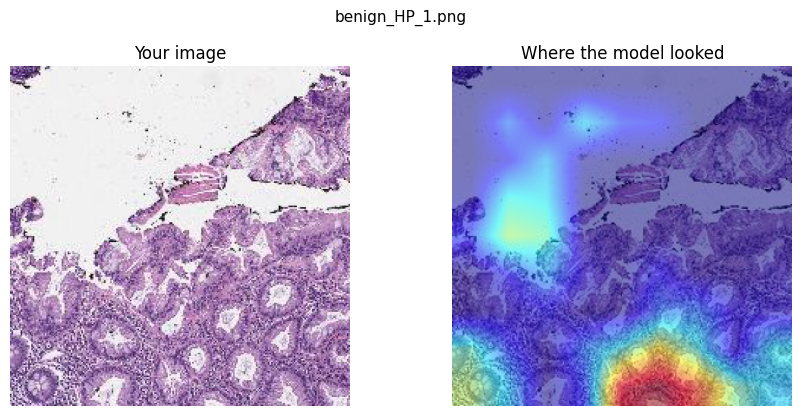

Type:
   Hyperplastic polyp (HP). This is a BENIGN (harmless) polyp.
What it is:
   A small, very common polyp, usually in the lower colon and rectum, made of extra but normal-
   looking lining cells.
Cancer risk:
   Very low. Small hyperplastic polyps in the rectum and sigmoid colon are not considered pre-
   cancerous.
What causes it:
   Extra growth of the colon lining cells, often with KRAS or BRAF gene changes. It becomes more
   common with age.
Risk factors:
   Age, smoking, obesity, alcohol and a low-fibre diet.
What to do next:
   Usually nothing beyond removal during colonoscopy, and routine screening as advised by the
   doctor. Large (10 mm or more) or right-sided hyperplastic polyps may need earlier follow-up,
   because they can look like SSL.
Healthy habits:
   Stop smoking, limit alcohol, keep a healthy weight, exercise regularly, eat fibre-rich food and
   less red or processed meat.
Disclaimer:
   Research prototype for education only. Not a medical diagnosis. Always

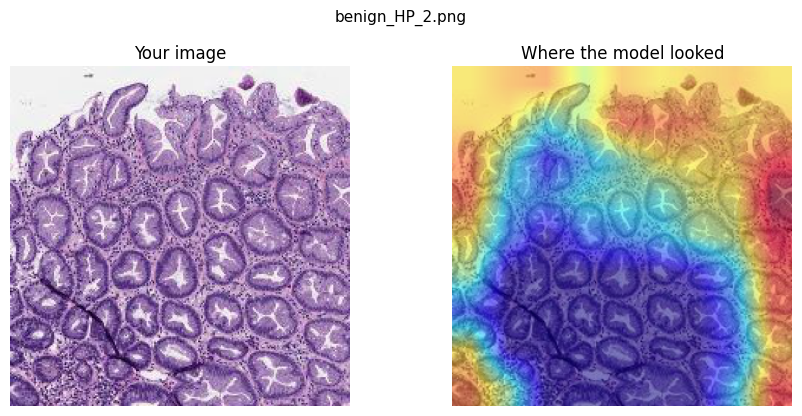

Type:
   Hyperplastic polyp (HP). This is a BENIGN (harmless) polyp.
What it is:
   A small, very common polyp, usually in the lower colon and rectum, made of extra but normal-
   looking lining cells.
Cancer risk:
   Very low. Small hyperplastic polyps in the rectum and sigmoid colon are not considered pre-
   cancerous.
What causes it:
   Extra growth of the colon lining cells, often with KRAS or BRAF gene changes. It becomes more
   common with age.
Risk factors:
   Age, smoking, obesity, alcohol and a low-fibre diet.
What to do next:
   Usually nothing beyond removal during colonoscopy, and routine screening as advised by the
   doctor. Large (10 mm or more) or right-sided hyperplastic polyps may need earlier follow-up,
   because they can look like SSL.
Healthy habits:
   Stop smoking, limit alcohol, keep a healthy weight, exercise regularly, eat fibre-rich food and
   less red or processed meat.
Disclaimer:
   Research prototype for education only. Not a medical diagnosis. Always

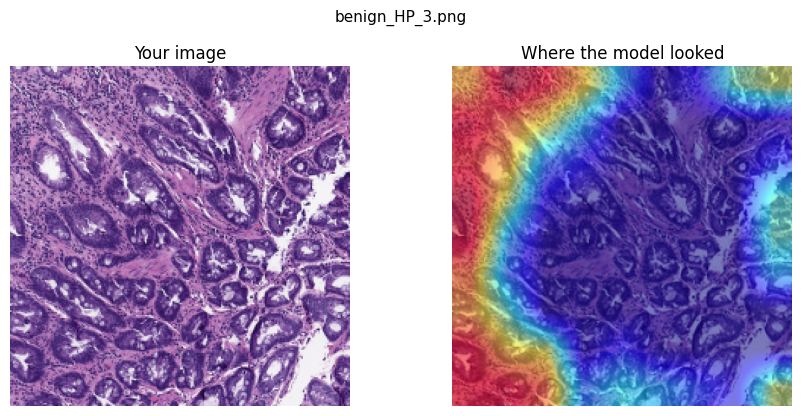

Type:
   Hyperplastic polyp (HP). This is a BENIGN (harmless) polyp.
What it is:
   A small, very common polyp, usually in the lower colon and rectum, made of extra but normal-
   looking lining cells.
Cancer risk:
   Very low. Small hyperplastic polyps in the rectum and sigmoid colon are not considered pre-
   cancerous.
What causes it:
   Extra growth of the colon lining cells, often with KRAS or BRAF gene changes. It becomes more
   common with age.
Risk factors:
   Age, smoking, obesity, alcohol and a low-fibre diet.
What to do next:
   Usually nothing beyond removal during colonoscopy, and routine screening as advised by the
   doctor. Large (10 mm or more) or right-sided hyperplastic polyps may need earlier follow-up,
   because they can look like SSL.
Healthy habits:
   Stop smoking, limit alcohol, keep a healthy weight, exercise regularly, eat fibre-rich food and
   less red or processed meat.
Disclaimer:
   Research prototype for education only. Not a medical diagnosis. Always

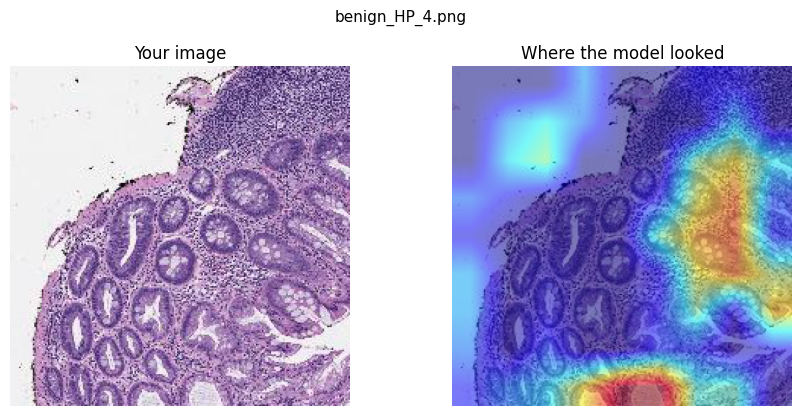

Type:
   Hyperplastic polyp (HP). This is a BENIGN (harmless) polyp.
What it is:
   A small, very common polyp, usually in the lower colon and rectum, made of extra but normal-
   looking lining cells.
Cancer risk:
   Very low. Small hyperplastic polyps in the rectum and sigmoid colon are not considered pre-
   cancerous.
What causes it:
   Extra growth of the colon lining cells, often with KRAS or BRAF gene changes. It becomes more
   common with age.
Risk factors:
   Age, smoking, obesity, alcohol and a low-fibre diet.
What to do next:
   Usually nothing beyond removal during colonoscopy, and routine screening as advised by the
   doctor. Large (10 mm or more) or right-sided hyperplastic polyps may need earlier follow-up,
   because they can look like SSL.
Healthy habits:
   Stop smoking, limit alcohol, keep a healthy weight, exercise regularly, eat fibre-rich food and
   less red or processed meat.
Disclaimer:
   Research prototype for education only. Not a medical diagnosis. Always

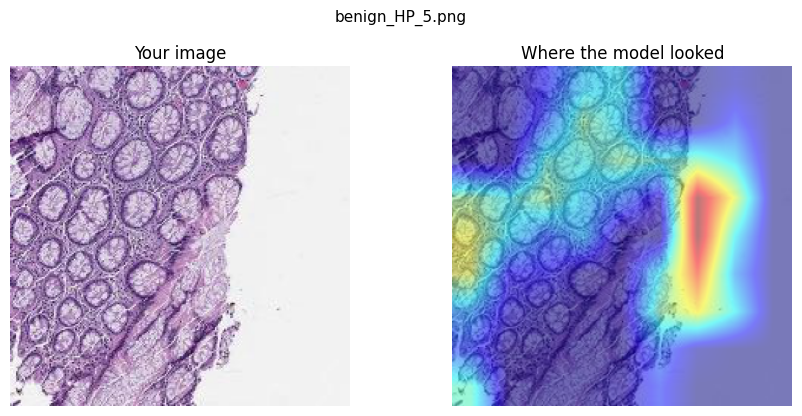

Type:
   Hyperplastic polyp (HP). This is a BENIGN (harmless) polyp.
What it is:
   A small, very common polyp, usually in the lower colon and rectum, made of extra but normal-
   looking lining cells.
Cancer risk:
   Very low. Small hyperplastic polyps in the rectum and sigmoid colon are not considered pre-
   cancerous.
What causes it:
   Extra growth of the colon lining cells, often with KRAS or BRAF gene changes. It becomes more
   common with age.
Risk factors:
   Age, smoking, obesity, alcohol and a low-fibre diet.
What to do next:
   Usually nothing beyond removal during colonoscopy, and routine screening as advised by the
   doctor. Large (10 mm or more) or right-sided hyperplastic polyps may need earlier follow-up,
   because they can look like SSL.
Healthy habits:
   Stop smoking, limit alcohol, keep a healthy weight, exercise regularly, eat fibre-rich food and
   less red or processed meat.
Disclaimer:
   Research prototype for education only. Not a medical diagnosis. Always

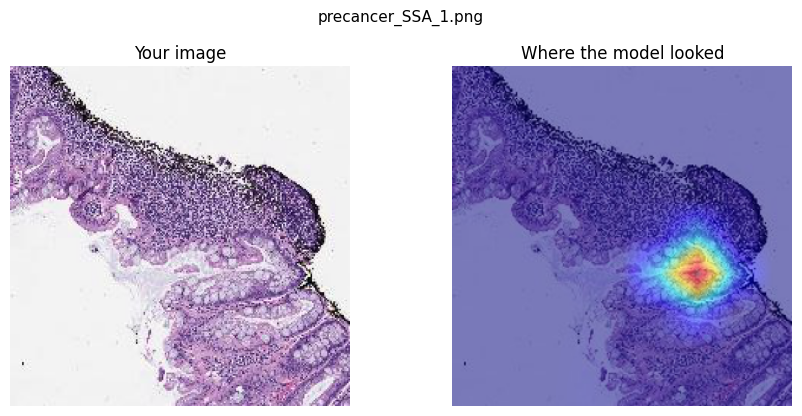

Type:
   Sessile serrated lesion (SSL), also called sessile serrated adenoma (SSA). This is a PRE-
   CANCEROUS polyp, not cancer yet.
What it is:
   A flat polyp, usually in the right (upper) part of the colon. Under the microscope its glands
   look saw-toothed (serrated) and widen at the bottom.
Cancer risk:
   It can slowly turn into colorectal cancer through the "serrated pathway". Up to about 30% of
   colorectal cancers are thought to start this way. Large lesions (10 mm or more) or lesions with
   dysplasia carry a higher risk.
What causes it:
   Gene changes in the lining cells: most SSLs carry a BRAF gene mutation and extra DNA methylation
   (CIMP), which can switch off DNA-repair genes such as MLH1.
Risk factors:
   Smoking (strongest link), age over 50, obesity, alcohol, and a family history of serrated polyps
   or colorectal cancer.
What to do next:
   1) Pathologist confirmation of the slide. 2) Complete removal of the polyp during colonoscopy, if
   not already done. 3

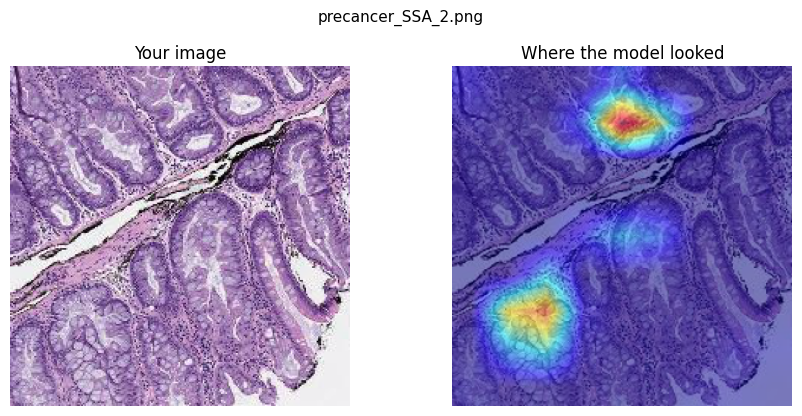

Type:
   Sessile serrated lesion (SSL), also called sessile serrated adenoma (SSA). This is a PRE-
   CANCEROUS polyp, not cancer yet.
What it is:
   A flat polyp, usually in the right (upper) part of the colon. Under the microscope its glands
   look saw-toothed (serrated) and widen at the bottom.
Cancer risk:
   It can slowly turn into colorectal cancer through the "serrated pathway". Up to about 30% of
   colorectal cancers are thought to start this way. Large lesions (10 mm or more) or lesions with
   dysplasia carry a higher risk.
What causes it:
   Gene changes in the lining cells: most SSLs carry a BRAF gene mutation and extra DNA methylation
   (CIMP), which can switch off DNA-repair genes such as MLH1.
Risk factors:
   Smoking (strongest link), age over 50, obesity, alcohol, and a family history of serrated polyps
   or colorectal cancer.
What to do next:
   1) Pathologist confirmation of the slide. 2) Complete removal of the polyp during colonoscopy, if
   not already done. 3

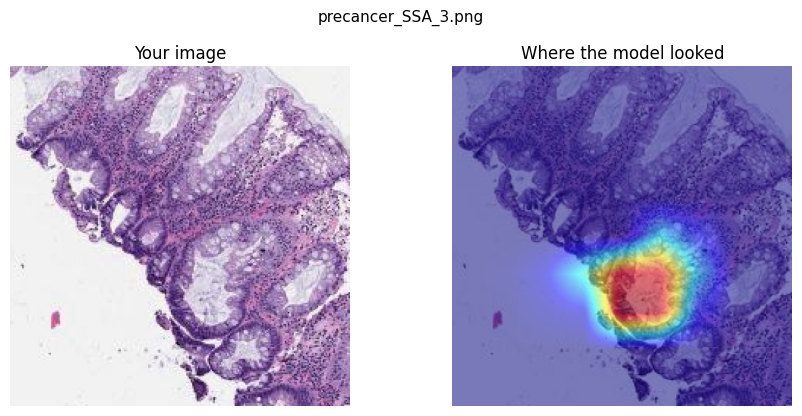

Type:
   Sessile serrated lesion (SSL), also called sessile serrated adenoma (SSA). This is a PRE-
   CANCEROUS polyp, not cancer yet.
What it is:
   A flat polyp, usually in the right (upper) part of the colon. Under the microscope its glands
   look saw-toothed (serrated) and widen at the bottom.
Cancer risk:
   It can slowly turn into colorectal cancer through the "serrated pathway". Up to about 30% of
   colorectal cancers are thought to start this way. Large lesions (10 mm or more) or lesions with
   dysplasia carry a higher risk.
What causes it:
   Gene changes in the lining cells: most SSLs carry a BRAF gene mutation and extra DNA methylation
   (CIMP), which can switch off DNA-repair genes such as MLH1.
Risk factors:
   Smoking (strongest link), age over 50, obesity, alcohol, and a family history of serrated polyps
   or colorectal cancer.
What to do next:
   1) Pathologist confirmation of the slide. 2) Complete removal of the polyp during colonoscopy, if
   not already done. 3

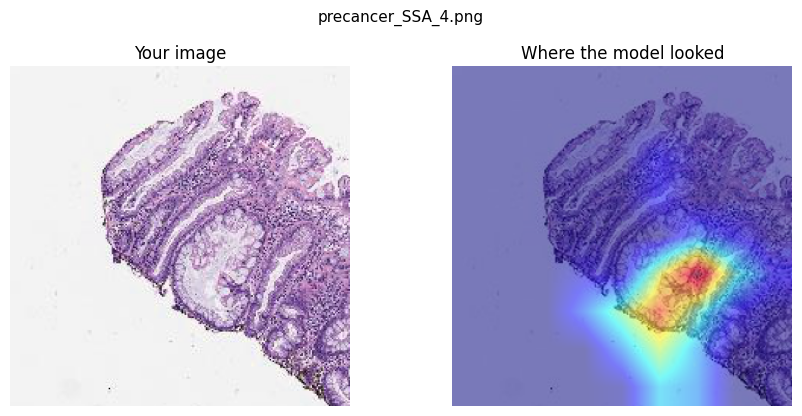

Type:
   Sessile serrated lesion (SSL), also called sessile serrated adenoma (SSA). This is a PRE-
   CANCEROUS polyp, not cancer yet.
What it is:
   A flat polyp, usually in the right (upper) part of the colon. Under the microscope its glands
   look saw-toothed (serrated) and widen at the bottom.
Cancer risk:
   It can slowly turn into colorectal cancer through the "serrated pathway". Up to about 30% of
   colorectal cancers are thought to start this way. Large lesions (10 mm or more) or lesions with
   dysplasia carry a higher risk.
What causes it:
   Gene changes in the lining cells: most SSLs carry a BRAF gene mutation and extra DNA methylation
   (CIMP), which can switch off DNA-repair genes such as MLH1.
Risk factors:
   Smoking (strongest link), age over 50, obesity, alcohol, and a family history of serrated polyps
   or colorectal cancer.
What to do next:
   1) Pathologist confirmation of the slide. 2) Complete removal of the polyp during colonoscopy, if
   not already done. 3

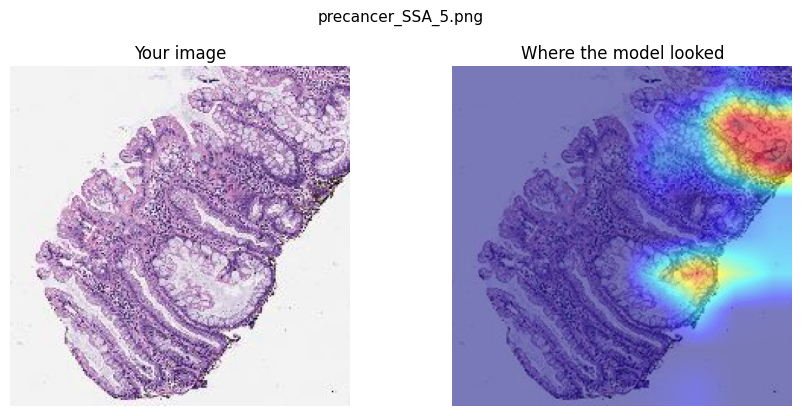

Type:
   Sessile serrated lesion (SSL), also called sessile serrated adenoma (SSA). This is a PRE-
   CANCEROUS polyp, not cancer yet.
What it is:
   A flat polyp, usually in the right (upper) part of the colon. Under the microscope its glands
   look saw-toothed (serrated) and widen at the bottom.
Cancer risk:
   It can slowly turn into colorectal cancer through the "serrated pathway". Up to about 30% of
   colorectal cancers are thought to start this way. Large lesions (10 mm or more) or lesions with
   dysplasia carry a higher risk.
What causes it:
   Gene changes in the lining cells: most SSLs carry a BRAF gene mutation and extra DNA methylation
   (CIMP), which can switch off DNA-repair genes such as MLH1.
Risk factors:
   Smoking (strongest link), age over 50, obesity, alcohol, and a family history of serrated polyps
   or colorectal cancer.
What to do next:
   1) Pathologist confirmation of the slide. 2) Complete removal of the polyp during colonoscopy, if
   not already done. 3

In [52]:
# ===== Get demo pictures from the MHIST TEST set (never used for training) =====
import torchvision.transforms as T
DEMO_DIR = '/kaggle/working/demo_images'
os.makedirs(DEMO_DIR, exist_ok=True)

test_table = get_split('test')
# clear examples: all 7 pathologists agreed
ssa_examples = test_table[(test_table['label'] == 1) & (test_table['agreement'] == 7)].sample(5, random_state=1)
hp_examples  = test_table[(test_table['label'] == 0) & (test_table['agreement'] == 7)].sample(5, random_state=1)

for i, path in enumerate(ssa_examples['path'], start=1):
    shutil.copy(path, f'{DEMO_DIR}/precancer_SSA_{i}.png')
for i, path in enumerate(hp_examples['path'], start=1):
    shutil.copy(path, f'{DEMO_DIR}/benign_HP_{i}.png')

# show them
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for col, path in enumerate(ssa_examples['path']):
    axes[0, col].imshow(Image.open(path)); axes[0, col].axis('off'); axes[0, col].set_title(f'precancer_SSA_{col + 1}', fontsize=9)
for col, path in enumerate(hp_examples['path']):
    axes[1, col].imshow(Image.open(path)); axes[1, col].axis('off'); axes[1, col].set_title(f'benign_HP_{col + 1}', fontsize=9)
plt.suptitle('Demo pictures (row 1: pre-cancer SSA, row 2: benign HP)'); plt.tight_layout(); plt.show()

print('Saved in', DEMO_DIR, '-> right panel: Output -> demo_images -> download')
print(sorted(os.listdir(DEMO_DIR)))

# check them directly (same output as uploading them)
for path in sorted(glob.glob(DEMO_DIR + '/*.png')):
    check_picture(path)

In [49]:
# ===================================================================================
# CHECK YOUR OWN PICTURES (one or more) -> early-detection result + explanation + PDF
# Run Steps 1-13 first (the models must be loaded). Then run this cell,
# click "Choose images", select one or more pictures, and the results appear below.
# ===================================================================================
import textwrap
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

UPLOAD_DIR = '/kaggle/working/uploads'
os.makedirs(UPLOAD_DIR, exist_ok=True)

# ---------- 1. Medical information for each result ----------
MEDICAL_INFO = {
    'SSA': [
        ('Type', 'Sessile serrated lesion (SSL), also called sessile serrated adenoma (SSA). '
                 'This is a PRE-CANCEROUS polyp, not cancer yet.'),
        ('What it is', 'A flat polyp, usually in the right (upper) part of the colon. Under the microscope its '
                       'glands look saw-toothed (serrated) and widen at the bottom.'),
        ('Cancer risk', 'It can slowly turn into colorectal cancer through the "serrated pathway". Up to about 30% '
                        'of colorectal cancers are thought to start this way. Large lesions (10 mm or more) or '
                        'lesions with dysplasia carry a higher risk.'),
        ('What causes it', 'Gene changes in the lining cells: most SSLs carry a BRAF gene mutation and extra DNA '
                           'methylation (CIMP), which can switch off DNA-repair genes such as MLH1.'),
        ('Risk factors', 'Smoking (strongest link), age over 50, obesity, alcohol, and a family history of '
                         'serrated polyps or colorectal cancer.'),
        ('What to do next', '1) Pathologist confirmation of the slide. 2) Complete removal of the polyp during '
                            'colonoscopy, if not already done. 3) Follow-up colonoscopy as advised by the '
                            'gastroenterologist, usually after 3 to 10 years depending on size and number; sooner '
                            'for lesions of 10 mm or more or with dysplasia.'),
        ('Healthy habits', 'Stop smoking, limit alcohol, keep a healthy weight, exercise regularly, eat fibre-rich '
                           'food and less red or processed meat.'),
    ],
    'HP': [
        ('Type', 'Hyperplastic polyp (HP). This is a BENIGN (harmless) polyp.'),
        ('What it is', 'A small, very common polyp, usually in the lower colon and rectum, made of extra but '
                       'normal-looking lining cells.'),
        ('Cancer risk', 'Very low. Small hyperplastic polyps in the rectum and sigmoid colon are not considered '
                        'pre-cancerous.'),
        ('What causes it', 'Extra growth of the colon lining cells, often with KRAS or BRAF gene changes. It '
                           'becomes more common with age.'),
        ('Risk factors', 'Age, smoking, obesity, alcohol and a low-fibre diet.'),
        ('What to do next', 'Usually nothing beyond removal during colonoscopy, and routine screening as advised '
                            'by the doctor. Large (10 mm or more) or right-sided hyperplastic polyps may need '
                            'earlier follow-up, because they can look like SSL.'),
        ('Healthy habits', 'Stop smoking, limit alcohol, keep a healthy weight, exercise regularly, eat fibre-rich '
                           'food and less red or processed meat.'),
    ],
}


# ---------- 2. Simple message: pre-cancer / stay calm / not sure / not tissue ----------
def get_status(is_ssa, refer, tissue_ok):
    leaning = 'pre-cancer (SSA)' if is_ssa else 'benign (HP)'
    if not tissue_ok:
        return ('#868e96', 'NOT A COLON TISSUE IMAGE',
                'Please upload a microscope image of a colon polyp (H&E stained). '
                'No medical result can be given for this picture.')
    if refer:
        return ('#f08c00', 'THE SYSTEM IS NOT SURE - PLEASE SEE A DOCTOR',
                f'The model leans towards {leaning}, but it is not confident. Do not worry, but please get this '
                'slide checked by a pathologist or doctor.')
    if is_ssa:
        return ('#e03131', 'PRE-CANCEROUS CHANGE FOUND (SSA)',
                'This is NOT cancer yet, but it is an early warning sign. If removed in time, cancer can be '
                'prevented. Please consult a gastroenterologist soon for removal of the polyp and follow-up.')
    return ('#2f9e44', 'STAY CALM - NOTHING SERIOUS FOUND',
            'This looks like a harmless (benign) hyperplastic polyp. No pre-cancerous change was found. '
            'Just continue your routine check-ups as advised by your doctor.')


def get_sections(is_ssa, refer, tissue_ok, title, message):
    sections = [('RESULT: ' + title, message)]
    if tissue_ok:
        sections += MEDICAL_INFO['SSA' if is_ssa else 'HP']
    sections.append(('Disclaimer', 'Research prototype for education only. Not a medical diagnosis. '
                                   'Always consult a doctor.'))
    return sections


# ---------- 3. Two-page PDF report ----------
def make_pdf(pdf_path, file_name, image, heatmap, probs, uncertainty, colour, sections):
    with PdfPages(pdf_path) as pdf:
        # page 1: images + result
        fig = plt.figure(figsize=(8.27, 11.69))
        fig.text(0.5, 0.96, 'Early Detection Report - Colorectal Polyp', ha='center', fontsize=15, weight='bold')
        fig.text(0.5, 0.935, f'File: {file_name}  |  Date: {datetime.datetime.now():%Y-%m-%d %H:%M}',
                 ha='center', fontsize=8, color='gray')
        ax1 = fig.add_axes([0.07, 0.58, 0.40, 0.32]); ax1.imshow(image); ax1.set_title('Your image'); ax1.axis('off')
        ax2 = fig.add_axes([0.53, 0.58, 0.40, 0.32]); ax2.imshow(heatmap); ax2.set_title('Where the model looked'); ax2.axis('off')
        fig.text(0.5, 0.53, sections[0][0].replace('RESULT: ', ''), ha='center', fontsize=14, weight='bold', color=colour)
        y = 0.50
        for line in textwrap.wrap(sections[0][1], 90):
            fig.text(0.5, y, line, ha='center', fontsize=10)
            y -= 0.02
        ax3 = fig.add_axes([0.20, 0.30, 0.60, 0.10])
        ax3.barh(['HP (benign)', 'SSA (pre-cancer)'], probs, color=['#2f9e44', '#e03131'])
        ax3.axvline(DECISION_THRESHOLD, color='k', ls='--', lw=0.8)
        ax3.set_xlim(0, 1); ax3.set_title('Probability (dashed line = decision threshold)', fontsize=9)
        fig.text(0.07, 0.24, f'Probability of pre-cancer (SSA): {probs[1]:.1%}', fontsize=10)
        fig.text(0.07, 0.22, f'Model uncertainty: {uncertainty:.3f}  (refer to doctor if above {REFER_THRESHOLD:.3f})', fontsize=10)
        fig.text(0.07, 0.17, 'Model: 3 x ConvNeXt-Base with evidential uncertainty, trained on MHIST '
                             '(3,152 images, 7 pathologists per image).', fontsize=8, color='gray')
        fig.text(0.07, 0.15, 'DISCLAIMER: research prototype for academic use only. Not a medical diagnosis.',
                 fontsize=8, color='gray')
        pdf.savefig(fig)
        plt.close(fig)

        # page 2: what does this result mean?
        fig = plt.figure(figsize=(8.27, 11.69))
        fig.text(0.5, 0.95, 'What does this result mean?', ha='center', fontsize=15, weight='bold')
        y = 0.90
        for heading, text in sections:
            fig.text(0.07, y, heading, fontsize=11, weight='bold', color=colour if heading.startswith('RESULT') else 'black')
            y -= 0.024
            for line in textwrap.wrap(text, 95):
                fig.text(0.07, y, line, fontsize=9.5)
                y -= 0.020
            y -= 0.015
        pdf.savefig(fig)
        plt.close(fig)


# ---------- 4. Check one picture ----------
def check_picture(path):
    file_name = os.path.basename(path)
    image = Image.open(path).convert('RGB')

    probs, uncertainty = predict_image(image)                 # 3 models x 8 views
    p_ssa = float(probs[1])
    is_ssa = p_ssa >= DECISION_THRESHOLD
    refer = uncertainty > REFER_THRESHOLD
    tissue_ok = looks_like_tissue(image)
    heatmap = gradcam_heatmap(FINAL_MODELS[0], 'convnext', FINAL_SIZE, image, int(is_ssa))

    colour, title, message = get_status(is_ssa, refer, tissue_ok)
    sections = get_sections(is_ssa, refer, tissue_ok, title, message)

    # show image + heatmap
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
    axes[0].imshow(image); axes[0].set_title('Your image'); axes[0].axis('off')
    axes[1].imshow(heatmap); axes[1].set_title('Where the model looked'); axes[1].axis('off')
    plt.suptitle(file_name, fontsize=11); plt.tight_layout(); plt.show()

    # big coloured message
    display(HTML(f'''
        <div style="border:3px solid {colour}; border-radius:12px; padding:16px; margin:8px 0;
                    background:{colour}15; font-family:Arial;">
            <div style="font-size:22px; font-weight:bold; color:{colour};">{title}</div>
            <div style="font-size:15px; margin-top:8px;">{message}</div>
            <div style="font-size:13px; margin-top:8px; color:#555;">
                Probability of pre-cancer: <b>{p_ssa:.1%}</b> &nbsp;|&nbsp; Uncertainty: <b>{uncertainty:.3f}</b>
            </div>
        </div>'''))

    # medical details
    for heading, text in sections[1:]:
        print(f'{heading}:')
        print(textwrap.fill(text, 100, initial_indent='   ', subsequent_indent='   '))

    # PDF report
    pdf_path = f"{REPORTS_DIR}/{os.path.splitext(file_name)[0]}_report.pdf"
    make_pdf(pdf_path, file_name, image, heatmap, probs, uncertainty, colour, sections)
    print('\nPDF report saved:', pdf_path)
    print('-' * 100)

    return {'file': file_name, 'result': title, 'p_ssa_%': round(100 * p_ssa, 1),
            'uncertainty': round(uncertainty, 3), 'refer_to_doctor': bool(refer),
            'tissue_image': tissue_ok, 'report_pdf': pdf_path}


# ---------- 5. Upload button ----------
upload_button = widgets.FileUpload(accept='image/*', multiple=True, description='Choose images')
result_area = widgets.Output()

def on_upload(change):
    with result_area:
        clear_output()
        files = upload_button.value
        if isinstance(files, dict):                            # older ipywidgets version
            files = [{'name': name, 'content': f['content']} for name, f in files.items()]
        print(f'{len(files)} picture(s) received\n')
        summary = []
        for f in files:
            path = os.path.join(UPLOAD_DIR, f['name'])
            with open(path, 'wb') as out:
                out.write(bytes(f['content']))
            try:
                summary.append(check_picture(path))
            except Exception as error:
                print(f"Could not read {f['name']}: {error}\n")
        if summary:
            print('\nSUMMARY OF ALL PICTURES')
            table = pd.DataFrame(summary)
            display(table.drop(columns=['report_pdf']))
            table.to_csv(REPORTS_DIR + '/uploaded_images_summary.csv', index=False)
            print('All PDF reports are in', REPORTS_DIR, '-> Output tab to download')

upload_button.observe(on_upload, names='value')
print('Click "Choose images" and select one or more pictures (.png / .jpg):')
display(upload_button, result_area)

Click "Choose images" and select one or more pictures (.png / .jpg):


FileUpload(value=(), accept='image/*', description='Choose images', multiple=True)

Output()

In [53]:
# ===================== Matched-sensitivity and calibration: proposed vs soft-label cross-entropy =====================
# Run in the same Kaggle notebook AFTER the main notebook steps (it only reads the saved *_preds.csv files).
# Fills: Table 5 row "Soft-label CE + temperature scaling", Section 3.7 and 3.8 [TBC] values.
import os, numpy as np, pandas as pd
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_curve, roc_auc_score, brier_score_loss

SEEDS = [0, 1, 2]
def run_name(arch, method, seed): return f'mhist_{arch}_base_{method}_s{seed}'
def load(method, split):
    ps = []
    for s in SEEDS:
        t = pd.read_csv(f'{RESULTS_DIR}/{run_name("convnext", method, s)}_{split}_preds.csv').sort_values('idx')
        ps.append(t['p1'].values); y = t['y'].values
    return y, np.mean(ps, 0)

def ece(y, p, bins=15):
    conf = np.maximum(p, 1 - p); correct = ((p >= 0.5).astype(int) == y)
    edges = np.linspace(0.5, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi) if lo > 0.5 else (conf >= lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def fit_T(y, p):
    z = logit(p)
    nll = lambda T: -np.mean(y * np.log(1 / (1 + np.exp(-z / T)) + 1e-12) + (1 - y) * np.log(1 - 1 / (1 + np.exp(-z / T)) + 1e-12))
    return minimize_scalar(nll, bounds=(0.05, 20), method='bounded').x
def scale(p, T): return 1 / (1 + np.exp(-logit(p) / T))
def thr_for_sens(y, p, target):            # highest threshold whose sensitivity >= target
    cands = np.sort(np.unique(p))[::-1]
    for t in cands:
        if ((p >= t) & (y == 1)).sum() / (y == 1).sum() >= target: return t
    return cands[-1]
def sens_spec(y, p, t):
    pred = (p >= t).astype(int)
    return 100 * ((pred == 1) & (y == 1)).sum() / (y == 1).sum(), 100 * ((pred == 0) & (y == 0)).sum() / (y == 0).sum(), 100 * (pred == y).mean()

out = {}
for name, method in [('Proposed (evidential)', 'proposed'), ('Soft-label CE', 'ce_soft')]:
    yv, pv = load(method, 'val'); yt, pt = load(method, 'test')
    T = fit_T(yv, pv); pts = scale(pt, T)
    out[name] = dict(yt=yt, pt=pt, T=T, ECE=ece(yt, pt), Brier=brier_score_loss(yt, pt),
                     ECE_TS=ece(yt, pts), Brier_TS=brier_score_loss(yt, pts), AUC=100 * roc_auc_score(yt, pt))

TARGET = 0.9056                                           # sensitivity of the proposed model at its Youden threshold
rows = []
for name, r in out.items():
    t = thr_for_sens(r['yt'], r['pt'], TARGET)
    se, sp, acc = sens_spec(r['yt'], r['pt'], t)
    rows.append({'Model': name, 'AUC %': r['AUC'], 'T': r['T'], 'ECE': r['ECE'], 'ECE after TS': r['ECE_TS'],
                 'Brier': r['Brier'], 'Brier after TS': r['Brier_TS'],
                 'Sens @ matched (%)': se, 'Spec @ matched (%)': sp, 'Acc @ matched (%)': acc})
res = pd.DataFrame(rows)
print('MATCHED-SENSITIVITY AND CALIBRATION (3-seed ensembles + TTA, MHIST test set)')
display(res.round(4))

# paired bootstrap for the specificity difference at matched sensitivity
rng = np.random.default_rng(0); a, b = out['Proposed (evidential)'], out['Soft-label CE']; diffs = []
for _ in range(2000):
    i = rng.integers(0, len(a['yt']), len(a['yt']))
    y = a['yt'][i]
    if y.sum() == 0 or (1 - y).sum() == 0: continue
    sa = sens_spec(y, a['pt'][i], thr_for_sens(y, a['pt'][i], TARGET))[1]
    sb = sens_spec(y, b['pt'][i], thr_for_sens(y, b['pt'][i], TARGET))[1]
    diffs.append(sa - sb)
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f'Specificity difference (proposed - soft-label CE) at matched sensitivity: '
      f'{rows[0]["Spec @ matched (%)"] - rows[1]["Spec @ matched (%)"]:+.2f} points, 95% CI [{lo:+.2f}, {hi:+.2f}] '
      f'-> {"significant" if lo > 0 or hi < 0 else "NOT significant"}')
res.to_csv(f'{RESULTS_DIR}/matched_calibration_analysis.csv', index=False)


MATCHED-SENSITIVITY AND CALIBRATION (3-seed ensembles + TTA, MHIST test set)


,Model,AUC %,T,ECE,ECE after TS,Brier,Brier after TS,Sens @ matched (%),Spec @ matched (%),Acc @ matched (%)
0,Proposed (evidential),97.2069,0.5205,0.0753,0.0303,0.0686,0.0648,90.8333,90.1135,90.3787
1,Soft-label CE,97.2749,0.3610,0.1097,0.0292,0.0814,0.0690,90.8333,90.5997,90.6858


Specificity difference (proposed - soft-label CE) at matched sensitivity: -0.49 points, 95% CI [-3.30, +3.52] -> NOT significant


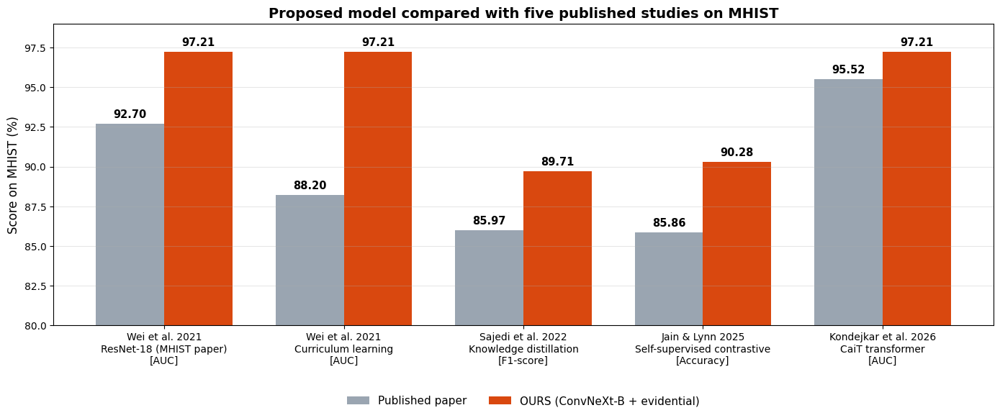

Saved: /kaggle/working/figures/compare_5_papers.png
Note: Jain & Lynn used their own 90:10 split and Kondejkar et al. used 5-fold CV; the others and ours use the official MHIST test set.


In [54]:
# ===================================================================================
# ONE GRAPH: OUR PROPOSED MODEL vs 5 PUBLISHED PAPERS ON MHIST
# Each paper reports a different metric, so for every paper we show
# the paper's number (grey) next to OUR number on the SAME metric (orange).
# ===================================================================================
import os
import numpy as np
import matplotlib.pyplot as plt

FIG_DIR = '/kaggle/working/figures' if os.path.exists('/kaggle/working') else 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

OURS = {'AUC': 97.21, 'Accuracy': 90.28, 'F1-score': 89.71}

# paper name,                                      metric,     paper value
papers = [
    ('Wei et al. 2021\nResNet-18 (MHIST paper)',      'AUC',      92.70),
    ('Wei et al. 2021\nCurriculum learning',          'AUC',      88.20),
    ('Sajedi et al. 2022\nKnowledge distillation',    'F1-score', 85.97),
    ('Jain & Lynn 2025\nSelf-supervised contrastive', 'Accuracy', 85.86),
    ('Kondejkar et al. 2026\nCaiT transformer',       'AUC',      95.52),
]

labels = [f'{name}\n[{metric}]' for name, metric, _ in papers]
paper_vals = [v for _, _, v in papers]
our_vals = [OURS[m] for _, m, _ in papers]

x = np.arange(len(papers))
w = 0.38
fig, ax = plt.subplots(figsize=(14, 6))
b1 = ax.bar(x - w / 2, paper_vals, w, color='#9aa5b1', label='Published paper')
b2 = ax.bar(x + w / 2, our_vals, w, color='#d9480f', label='OURS (ConvNeXt-B + evidential)')
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.25, f'{b.get_height():.2f}',
                ha='center', va='bottom', fontsize=10.5, weight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylim(80, 99)
ax.set_ylabel('Score on MHIST (%)', fontsize=12)
ax.set_title('Proposed model compared with five published studies on MHIST', fontsize=14, weight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=11, frameon=False)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/compare_5_papers.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved:', f'{FIG_DIR}/compare_5_papers.png')
print('Note: Jain & Lynn used their own 90:10 split and Kondejkar et al. used 5-fold CV; '
      'the others and ours use the official MHIST test set.')

In [55]:
# ===================== CELL R1: setup =====================
# New loss variants for the ablation + helper functions used by all reviewer cells.
from scipy.optimize import minimize_scalar
from scipy.stats import spearmanr, ttest_ind
from sklearn.metrics import roc_curve, brier_score_loss

EVIDENTIAL_METHODS = ('proposed', 'evid_hard', 'evid_soft')
NICE_NAME.update({('convnext', 'evid_hard'): 'Evidential, hard labels (plain EDL)',
                  ('convnext', 'evid_soft'): 'Evidential, soft labels (no agreement weight)'})

def evidential_loss_variant(logits, y, q, epoch, weights, soft=True, agreement=True):
    alpha = F.softplus(logits) + 1
    S = alpha.sum(1, keepdim=True)
    p = alpha / S
    hard_target = F.one_hot(y, 2).float()
    target = torch.stack([1 - q, q], dim=1) if soft else hard_target
    error = ((target - p) ** 2).sum(1) + (p * (1 - p) / (S + 1)).sum(1)
    kl = kl_to_uniform(hard_target + (1 - hard_target) * alpha)
    kl_weight = (2 * q - 1).abs() if agreement else torch.ones_like(q)
    kl_strength = min(1.0, epoch / KL_WARMUP_EPOCHS)
    return ((error + kl_strength * kl_weight * kl) * weights[y]).mean()

def compute_loss(logits, y, q, method, epoch, weights):          # replaces the notebook version
    if method == 'baseline':
        return F.cross_entropy(logits, y, weight=weights, label_smoothing=0.1)
    if method == 'evid_hard':                                     # plain evidential loss (hard labels)
        return evidential_loss_variant(logits, y, q, epoch, weights, soft=False, agreement=False)
    if method == 'evid_soft':                                     # soft labels, no agreement weighting
        return evidential_loss_variant(logits, y, q, epoch, weights, soft=True, agreement=False)
    return evidential_loss_variant(logits, y, q, epoch, weights, soft=True, agreement=True)  # proposed

def get_probabilities(logits, method):                            # replaces the notebook version
    if method in EVIDENTIAL_METHODS:
        alpha = F.softplus(logits) + 1
        S = alpha.sum(1, keepdim=True)
        return alpha / S, (2 / S).squeeze(1)
    p = F.softmax(logits, dim=1)
    return p, -(p * torch.log(p.clamp_min(1e-12))).sum(1) / math.log(2)

def binary_entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p)) / np.log(2)

def ensemble2(arch, method, split):
    tables = read_predictions(arch, method, split)
    out = tables[0][['idx', 'y', 'n_ssa', 'agreement']].copy()
    out['p1'] = np.mean([t['p1'].values for t in tables], axis=0)
    out['unc'] = (np.mean([t['unc'].values for t in tables], axis=0) if method in EVIDENTIAL_METHODS
                  else binary_entropy(out['p1'].values))
    return out

def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(min(thr[np.argmax(tpr - fpr)], 1.0))

def full_report(y, p, unc, agreement, threshold, refer_fraction=0.20):
    m = compute_metrics(y, p, threshold)
    pred = (p >= threshold).astype(int)
    errors = (pred != y).astype(int)
    keep = np.argsort(unc)[: int(round(len(y) * (1 - refer_fraction)))]
    rho, pval = spearmanr(unc, 7 - agreement)
    return {'AUC': 100 * m['auc'], 'Acc': 100 * m['acc'], 'Sens': 100 * m['sensitivity'],
            'Spec': 100 * m['specificity'], 'F1': 100 * m['macro_f1'],
            'ECE': expected_calibration_error(y, p), 'Brier': brier_score_loss(y, p),
            'Spearman rho': rho,
            'Error-detection AUROC': roc_auc_score(errors, unc) if 0 < errors.sum() < len(errors) else np.nan,
            'Acc @20% referred': 100 * accuracy_score(y[keep], pred[keep])}
print('Reviewer setup ready.')

Reviewer setup ready.


In [56]:
# ===================== CELL R2: ablation training =====================
# Trains the two missing loss variants (3 seeds each) with exactly the same settings
# as the proposed model. Already-trained runs are skipped.
ALLOW_TRAINING = True
for method in ['evid_hard', 'evid_soft']:
    for seed in SEEDS:
        name = train_model('convnext', method, seed)
        save_predictions(name)
ALLOW_TRAINING = False
print('Ablation models trained and predicted.')

mhist_convnext_base_evid_hard_s0: already trained -> skipped
mhist_convnext_base_evid_hard_s1: already trained -> skipped
mhist_convnext_base_evid_hard_s2: already trained -> skipped
mhist_convnext_base_evid_soft_s0: already trained -> skipped
mhist_convnext_base_evid_soft_s1: already trained -> skipped
mhist_convnext_base_evid_soft_s2: already trained -> skipped
Ablation models trained and predicted.


In [57]:
# ===================== CELL R3: ablation table =====================
ABLATION = [('convnext', 'baseline'), ('convnext', 'evid_hard'), ('convnext', 'evid_soft'), ('convnext', 'proposed')]
rows = []
for arch, method in ABLATION:
    val, test = ensemble2(arch, method, 'val'), ensemble2(arch, method, 'test')
    thr = youden_threshold(val['y'].values, val['p1'].values)
    per_seed_auc = [100 * roc_auc_score(t['y'], t['p1']) for t in read_predictions(arch, method, 'test')]
    row = {'Loss': NICE_NAME[(arch, method)],
           'AUC per seed (mean ± SD)': f'{np.mean(per_seed_auc):.2f} ± {np.std(per_seed_auc):.2f}'}
    row.update(full_report(test['y'].values, test['p1'].values, test['unc'].values,
                           test['agreement'].values, thr))
    rows.append(row)
ablation = pd.DataFrame(rows)
print('ABLATION (ConvNeXt-B, 3-seed ensemble + TTA, Youden threshold from validation)')
display(ablation.round(3))
ablation.to_csv(RESULTS_DIR + '/reviewer_ablation.csv', index=False)

ABLATION (ConvNeXt-B, 3-seed ensemble + TTA, Youden threshold from validation)


,Loss,AUC per seed (mean ± SD),AUC,Acc,Sens,Spec,F1,ECE,Brier,Spearman rho,Error-detection AUROC,Acc @20% referred
0,ConvNeXt-B baseline,95.73 ± 0.13,96.374,89.458,90.278,88.979,88.873,0.051,0.074,0.483,0.869,95.780
1,"Evidential, hard labels (plain EDL)",95.90 ± 0.62,96.257,89.560,92.778,87.682,89.069,0.061,0.088,0.410,0.829,94.246
2,"Evidential, soft labels (no agreement weight)",96.70 ± 0.15,97.129,89.662,94.444,86.872,89.229,0.068,0.069,0.551,0.900,96.419
3,Proposed (ConvNeXt + evidential),96.81 ± 0.16,97.207,90.276,90.556,90.113,89.706,0.075,0.069,0.562,0.888,96.931


In [59]:
# ===================== CELL R4: per-seed results (with and without TTA) =====================
# Single models, mean ± SD over the 3 seeds; also WITHOUT test-time augmentation,
# so the numbers can be compared fairly with single-model results in other papers.
import torchvision.transforms as T
def single_model_predictions(arch, method, seed, use_tta):
    model, ckpt = load_model(run_name(arch, method, seed))
    table = get_split('test')
    loader = make_loader(table, get_test_transform(ckpt['size']), shuffle=False, batch_size=64)
    probs, unc, index = predict(model, loader, method, use_tta=use_tta)
    del model; torch.cuda.empty_cache()
    return table['label'].values[index], probs[:, 1]

rows, seed_auc = [], {}
for arch, method in EXPERIMENTS:
    for use_tta in [False, True]:
        res = []
        for seed in SEEDS:
            if use_tta:
                t = read_predictions(arch, method, 'test')[SEEDS.index(seed)]
                y, p = t['y'].values, t['p1'].values
            else:
                y, p = single_model_predictions(arch, method, seed, use_tta=False)
            res.append(compute_metrics(y, p, 0.5))
        res = pd.DataFrame(res)
        seed_auc[(arch, method, use_tta)] = 100 * res['auc'].values
        row = {'Model': NICE_NAME[(arch, method)], 'TTA': 'yes' if use_tta else 'no'}
        for k, label in [('auc', 'AUC'), ('acc', 'Acc'), ('sensitivity', 'Sens'), ('specificity', 'Spec'), ('macro_f1', 'F1')]:
            row[label] = f'{100 * res[k].mean():.2f} ± {100 * res[k].std(ddof=0):.2f}'
        rows.append(row)
per_seed = pd.DataFrame(rows)
print('SINGLE MODELS: mean ± SD over 3 seeds (threshold 0.5)')
display(per_seed)
per_seed.to_csv(RESULTS_DIR + '/reviewer_per_seed.csv', index=False)

for tta in [False, True]:
    a, b = seed_auc[('convnext', 'proposed', tta)], seed_auc[('convnext', 'baseline', tta)]
    t_stat, p_val = ttest_ind(a, b)
    print(f"TTA={tta}: proposed - ConvNeXt AUC gap = {a.mean() - b.mean():.2f} points "
          f"(seed SD {a.std():.2f} / {b.std():.2f}); t-test over the 3 seeds p = {p_val:.4f}")

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

...

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

SINGLE MODELS: mean ± SD over 3 seeds (threshold 0.5)


,Model,TTA,AUC,Acc,Sens,Spec,F1
0,ConvNeXt-B baseline,no,94.35 ± 0.59,88.02 ± 0.38,85.00 ± 2.04,89.79 ± 1.15,87.20 ± 0.43
1,ConvNeXt-B baseline,yes,95.73 ± 0.13,89.22 ± 0.21,86.48 ± 1.51,90.82 ± 0.67,88.47 ± 0.27
2,Swin-B baseline,no,93.56 ± 0.60,85.91 ± 1.03,76.20 ± 6.69,91.57 ± 2.66,84.48 ± 1.50
3,Swin-B baseline,yes,95.09 ± 0.55,87.96 ± 1.10,78.80 ± 6.22,93.30 ± 2.06,86.72 ± 1.54
4,Proposed (ConvNeXt + evidential),no,96.32 ± 0.22,89.90 ± 0.34,87.59 ± 3.69,91.25 ± 2.21,89.20 ± 0.38
5,Proposed (ConvNeXt + evidential),yes,96.81 ± 0.16,90.65 ± 0.84,88.24 ± 2.82,92.06 ± 2.73,90.00 ± 0.78


TTA=False: proposed - ConvNeXt AUC gap = 1.97 points (seed SD 0.22 / 0.59); t-test over the 3 seeds p = 0.0115
TTA=True: proposed - ConvNeXt AUC gap = 1.08 points (seed SD 0.16 / 0.13); t-test over the 3 seeds p = 0.0018


In [61]:
# ===================== CELL R5: other uncertainty methods =====================
# (a) Deep ensemble: the ConvNeXt cross-entropy baseline averaged over 3 seeds x 8 TTA views,
#     uncertainty = normalised predictive entropy (this is how the baselines were evaluated).
# (b) MC dropout: dropout + drop-path kept ON at test time, T = 10 passes, single model per seed.
# (c) Temperature scaling: one temperature fitted on the VALIDATION set (NLL), applied to test.
MC_PASSES = 10

@torch.no_grad()
def mc_dropout_predict(model, loader, passes=MC_PASSES):
    model.eval()
    for m in model.modules():                                     # switch dropout layers back on
        if isinstance(m, nn.Dropout) or 'DropPath' in type(m).__name__:
            m.train()
    all_p, all_idx = [], []
    for x, y, q, index in tqdm(loader, desc='MC dropout', leave=False):
        x = x.to(DEVICE)
        p = 0
        for _ in range(passes):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            p = p + F.softmax(logits.float(), dim=1)[:, 1]
        all_p.append((p / passes).cpu()); all_idx.append(index)
    model.eval()
    return torch.cat(all_p).numpy(), torch.cat(all_idx).numpy()

def mc_dropout_split(split):
    ps = []
    for seed in SEEDS:
        model, ckpt = load_model(run_name('convnext', 'baseline', seed))
        table = get_split(split)
        loader = make_loader(table, get_test_transform(ckpt['size']), shuffle=False, batch_size=64)
        p, idx = mc_dropout_predict(model, loader)
        ps.append(pd.DataFrame({'idx': idx, 'p1': p}).sort_values('idx')['p1'].values)
        del model; torch.cuda.empty_cache()
    return ps                                                   # one array per seed

def fit_temperature(y, p):
    logit = np.log(np.clip(p, 1e-6, 1 - 1e-6) / np.clip(1 - p, 1e-6, 1))
    nll = lambda T: -np.mean(y * np.log(1 / (1 + np.exp(-logit / T)) + 1e-12)
                             + (1 - y) * np.log(1 - 1 / (1 + np.exp(-logit / T)) + 1e-12))
    return minimize_scalar(nll, bounds=(0.05, 20), method='bounded').x

def apply_temperature(p, T):
    logit = np.log(np.clip(p, 1e-6, 1 - 1e-6) / np.clip(1 - p, 1e-6, 1))
    return 1 / (1 + np.exp(-logit / T))

test_base, val_base = ensemble2('convnext', 'baseline', 'test'), ensemble2('convnext', 'baseline', 'val')
test_prop, val_prop = ensemble2('convnext', 'proposed', 'test'), ensemble2('convnext', 'proposed', 'val')
y, agr = test_base['y'].values, test_base['agreement'].values
rows = []

def add_row(name, val_p, test_p, test_unc):
    thr = youden_threshold(val_base['y'].values if 'proposed' not in name.lower() else val_prop['y'].values, val_p)
    r = {'Method': name}
    r.update(full_report(y, test_p, test_unc, agr, thr))
    rows.append(r)

# MC dropout: metrics averaged over the 3 single models
mc_test, mc_val = mc_dropout_split('test'), mc_dropout_split('val')
mc_rows = []
for pt, pv in zip(mc_test, mc_val):
    thr = youden_threshold(val_base['y'].values, pv)
    mc_rows.append(full_report(y, pt, binary_entropy(pt), agr, thr))
mc_mean = pd.DataFrame(mc_rows).mean().to_dict(); mc_mean = {'Method': 'MC dropout (single ConvNeXt, T=10, mean of 3 seeds)', **mc_mean}
rows.append(mc_mean)

add_row('Deep ensemble (3 x ConvNeXt CE + TTA, entropy)', val_base['p1'].values, test_base['p1'].values,
        binary_entropy(test_base['p1'].values))
T_base = fit_temperature(val_base['y'].values, val_base['p1'].values)
p_ts = apply_temperature(test_base['p1'].values, T_base)
add_row(f'Deep ensemble + temperature scaling (T={T_base:.2f})',
        apply_temperature(val_base['p1'].values, T_base), p_ts, binary_entropy(p_ts))
add_row('Proposed (evidential, u = 2/S)', val_prop['p1'].values, test_prop['p1'].values, test_prop['unc'].values)
T_prop = fit_temperature(val_prop['y'].values, val_prop['p1'].values)
add_row(f'Proposed + temperature scaling (T={T_prop:.2f})',
        apply_temperature(val_prop['p1'].values, T_prop), apply_temperature(test_prop['p1'].values, T_prop),
        test_prop['unc'].values)

unc_table = pd.DataFrame(rows)
print('UNCERTAINTY METHODS (MHIST test set). Higher rho / error-detection AUROC / referral accuracy = better; lower ECE / Brier = better')
display(unc_table.round(4))
unc_table.to_csv(RESULTS_DIR + '/reviewer_uncertainty_methods.csv', index=False)

MC dropout:   0%|          | 0/16 [00:00<?, ?it/s]

MC dropout:   0%|          | 0/16 [00:00<?, ?it/s]

MC dropout:   0%|          | 0/16 [00:00<?, ?it/s]

MC dropout:   0%|          | 0/6 [00:00<?, ?it/s]

MC dropout:   0%|          | 0/6 [00:00<?, ?it/s]

MC dropout:   0%|          | 0/6 [00:00<?, ?it/s]

UNCERTAINTY METHODS (MHIST test set). Higher rho / error-detection AUROC / referral accuracy = better; lower ECE / Brier = better


,Method,AUC,Acc,Sens,Spec,F1,ECE,Brier,Spearman rho,Error-detection AUROC,Acc @20% referred
0,"MC dropout (single ConvNeXt, T=10, mean of 3 s...",94.6397,86.3187,91.6667,83.1983,85.8211,0.0462,0.0890,0.3938,0.8359,94.0324
1,"Deep ensemble (3 x ConvNeXt CE + TTA, entropy)",96.3740,89.4575,90.2778,88.9789,88.8726,0.0511,0.0744,0.4833,0.8689,95.7801
2,Deep ensemble + temperature scaling (T=0.62),96.3740,89.4575,90.2778,88.9789,88.8726,0.0370,0.0750,0.4833,0.8689,95.7801
3,"Proposed (evidential, u = 2/S)",97.2069,90.2764,90.5556,90.1135,89.7059,0.0753,0.0686,0.5623,0.8879,96.9309
4,Proposed + temperature scaling (T=0.52),97.2069,90.2764,90.5556,90.1135,89.7059,0.0303,0.0648,0.5623,0.8879,96.9309


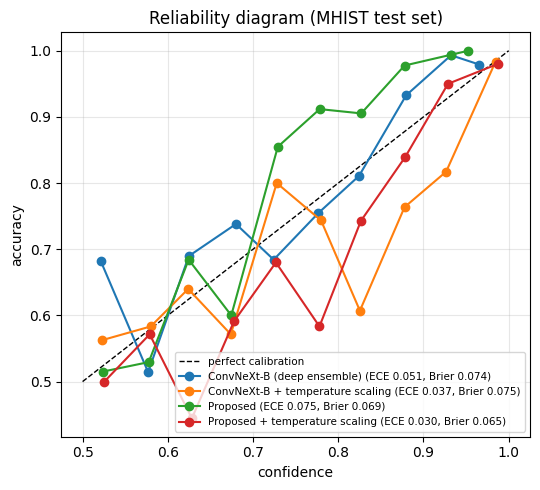

In [62]:
# ===================== CELL R6: calibration figure =====================
def reliability_points(y, p, bins=10):
    conf = np.maximum(p, 1 - p); correct = ((p >= 0.5).astype(int) == y)
    edges = np.linspace(0.5, 1, bins + 1); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf >= lo) & (conf <= hi)
        if m.sum() > 5:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return xs, ys

curves = [('ConvNeXt-B (deep ensemble)', test_base['p1'].values),
          ('ConvNeXt-B + temperature scaling', p_ts),
          ('Proposed', test_prop['p1'].values),
          ('Proposed + temperature scaling', apply_temperature(test_prop['p1'].values, T_prop))]
plt.figure(figsize=(5.5, 5))
plt.plot([0.5, 1], [0.5, 1], 'k--', lw=1, label='perfect calibration')
for name, p in curves:
    xs, ys = reliability_points(y, p)
    plt.plot(xs, ys, marker='o', label=f'{name} (ECE {expected_calibration_error(y, p):.3f}, Brier {brier_score_loss(y, p):.3f})')
plt.xlabel('confidence'); plt.ylabel('accuracy'); plt.title('Reliability diagram (MHIST test set)')
plt.legend(fontsize=7.5); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(FIGURES_DIR + '/reviewer_reliability.png', dpi=200); plt.show()